[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/00_isotropic_reslicing_and_polar_alignment.ipynb)

# Companion Notebook 00 — Canonical Geometric Preprocessing: Isotropic Reslicing & Polar N–S Alignment ($f = f_2 \circ f_1$)

*Pre-Segmentation Representation Study for the BMED365 Technical Report: **Differentiable Neurosymbolic AI for Semi-Verifiable 3D Biomedical Instance Segmentation** (`../neurosymbolic-kiwi-report.pdf`)*  
*Geometric formulation sketched at **Stilleskriving HKS (26/11-26)** — generates Figures `fig00a`–`fig00e` and quantitative audit `../results/nb00_canonical_transform_audit.json`*

### Scientific Motivation & Transformation Hypothesis
The archival 2005 UiB 7 T Bruker Pharmascan RARE kiwifruit MRI (`256 × 256 × 128`) was acquired with **anisotropic voxels** ($0.2344 \times 0.2344 \times 0.5000\text{ mm}^3$, slice-thickness aspect ratio $2.133:1$) and with the intact fruit resting **obliquely tilted** inside the scanner bore relative to the imaging $z$-axis. Before performing manual 3D curation or training automated neurosymbolic instance segmenters (`Notebooks 01–05`), we explore a principled **two-stage geometric normalization**:

$$f = f_2 \circ f_1 : \Omega_{\text{native}} \longrightarrow \Omega_{\text{canon}}$$

1. **$f_1$ — Isotropic Reslicing:** Resample the anisotropic $0.2344 \times 0.2344 \times 0.5000\text{ mm}^3$ lattice onto an **isotropic cubic lattice** ($s_{\text{iso}} = 0.2344\text{ mm}$ preserving native in-plane detail $1:1$; also benchmarked against $0.30\text{ mm}$ and $0.50\text{ mm}$).
2. **$f_2$ — Rigid Polar Alignment ($R \in SO(3),\,\mathbf{t} \in \mathbb{R}^3$):** Estimate the kiwifruit's intrinsic **North–South (N–S) polar axis** and rigidly align it strictly parallel to the canonical $z'$-axis (`x' = 0, y' = 0`), centering the equatorial plane at `z' = 0`.
3. **Invertibility ($f^{-1} = f_1^{-1} \circ f_2^{-1}$):** Transform instance-segmented 3D seeds (both the `98` curated Micro-Ground-Truth seeds and the `749` whole-fruit Neurosymbolic predictions) **back onto the original native `256 × 256 × 128` acquisition** with bit-identical scanner `sform` affine.

### What This Notebook Tests Empirically
- **Section 1 (Polar Axis Discovery):** Why naive outer-fruit PCA fails by $>17^\circ$ (near-spherical berry + 7 T RF $B_1$ polar shading), why slice-centroid regression underestimates tilt via ellipsoid-slicing bias, and why the **internal fibrous columella 3D centerline** locks onto the true botanical N–S poles with **$0.13\text{ mm}$ RMS straightness**!
- **Section 2 (Single-Pass Composite Pullback vs. Sequential Resampling):** Why implementing $f = f_2 \circ f_1$ as a **single $4\times 4$ homogeneous pullback** with **cubic B-spline** interpolation outperforms two-pass trilinear resampling by **$\approx +7\text{ dB}$ PSNR** and preserves $>90\%$ of high-frequency seed-edge gradient energy, plus an **isotropic spacing trade-off audit** (`0.234 / 0.300 / 0.500 mm`).
- **Section 3 (Implications for the `98` Micro-GT & `749` Whole-Fruit Seeds):** Head-to-head comparison of **Nearest-Neighbor (`order=0`)**, **Per-Instance Soft-Linear**, **Soft-Cubic**, and **Index-Space Cubic SDF** label warping (exposing curvature-driven shrinkage and the anisotropic physical-SDF pitfall), plus exact round-trip invertibility ($f^{-1} \circ f$) and 3D seed orientation analysis.
- **Section 4 (Botanical Visualization & Manual Segmentation Ergonomics):** Cylindrical **Mercator unrolling** $(\theta', z')$ contrasting tilted native space (sinusoidal carpel drift) against canonical N–S space (dead-vertical botanical carpel meridians from South Pole to North Pole).
- **Section 5 (3-Seed + Whole-Organ OOD Canonical Ablation & $f^{-1}$ Back-Projection):** Controlled **3-seed (`2027, 2028, 2029`)** ablation comparing `AdditiveBayesOrganNet3D` trained in native anisotropic space vs. canonical isotropic N–S space and mapped back via $f^{-1}$ onto the unaltered original `test_gt` (`52` held-out seeds), contrasting **discrete label pullback** $f^{-1}(\hat{L})$ vs. **continuous soft pullback** $f^{-1}(\hat{p}, \hat{d})$ (mean $\pm$ SD) alongside **unmasked whole-organ OOD safety** (polar-cap FPs, non-pericarp OOD volume in $\text{mm}^3$, and raw whole-fruit seed count) and the tilted-ROI prism caveat.
- **Section 6 (Decision Guide & Optional `MyStuff/` NIfTI Export for Freeview / ITK-SNAP / 3D Slicer):** Clear recommendations on when canonical space shines vs. when native space should be retained, plus a 1-flag git-safe NIfTI export for interactive 3D inspection.

## 0. Environment Setup: Portable Runtime, Shared Library & 3D Geometry Stack

### Conceptual & Practical Motivation
To keep Notebook `00` strictly synchronized with Companion Notebooks `01`–`05` (`kiwi_ns_lib.py`) without duplicating data loaders or evaluation code:

- **Zero-drift shared library (`kiwi_ns_lib.py`):** Automatically imported locally or fetched from GitHub `main` in Google Colab. We do **not** modify `kiwi_ns_lib.py`, keeping Notebooks `01`–`05` bit-reproducible while building all new $f = f_2 \circ f_1$ geometric operators cleanly here.
- **Cross-platform compute & memory budget:** Automatically selects `CUDA -> Apple Silicon MPS -> CPU`. Peak RAM stays under `~2.5 GB` (`256 × 256 × 288` `float32` = `75.5 MB`), compatible with both local workstations and free Google Colab (12 GB RAM / T4 GPU).
- **Outputs:** Publication figures are saved to `../figures/fig00a..e_*.png` and structured metrics to `../results/nb00_canonical_transform_audit.json`.

In [1]:
import importlib.util
import json
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

# Auto-fetch shared library `kiwi_ns_lib.py` if opened standalone in Google Colab
if not Path("kiwi_ns_lib.py").exists():
    for cand in [
        Path("docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
        Path("Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"),
    ]:
        if cand.exists():
            sys.path.insert(0, str(cand.parent.resolve()))
            break
    else:
        url = (
            "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/"
            "Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/notebooks/kiwi_ns_lib.py"
        )
        print("Downloading kiwi_ns_lib.py from GitHub main for Colab session...")
        urllib.request.urlretrieve(url, "kiwi_ns_lib.py")

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

for pkg in ("nibabel", "torch"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy import ndimage as ndi
from skimage import filters, measure

import kiwi_ns_lib as kns

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
})

T_NB_START = time.perf_counter()
DEVICE = kns.get_best_device()
FIG_DIR, RES_DIR = kns.resolve_report_dirs()

# Load intact 7T RARE MRI + curated 3D Micro-GT (98 seeds)
ds = kns.load_kiwi_dataset()
vol = ds.vol
gt_full = ds.gt_full
sp_orig = np.array(ds.spacing, dtype=np.float64)
A_orig = ds.affine.copy()

# Also resolve the whole-fruit 749-seed Neurosymbolic prediction (NB 04 output) for whole-organ round-trip verification
pred_wf_path = RES_DIR / "kiwi_neurosymbolic_pred_labels.nii.gz"
if not pred_wf_path.exists():
    wf_url = (
        "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/"
        "Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results/kiwi_neurosymbolic_pred_labels.nii.gz"
    )
    print("Downloading whole-fruit Neurosymbolic prediction NIfTI for Colab session...")
    urllib.request.urlretrieve(wf_url, pred_wf_path)
pred_wf_img = nib.load(str(pred_wf_path))
pred_wf_full = np.rint(np.asarray(pred_wf_img.dataobj)).astype(np.uint16)

print(f"Runtime device : {DEVICE}")
print(f"MRI shape      : {vol.shape} | spacing = {tuple(round(float(s), 4) for s in sp_orig)} mm | aspect z/xy = {sp_orig[2]/sp_orig[0]:.3f}x")
print(f"Micro-GT seeds : {len(np.unique(gt_full)) - 1} | Whole-fruit NB04 pred seeds: {len(np.unique(pred_wf_full)) - 1}")
print(f"sform check    : max |A_MRI - A_GT| = {ds.gt_affine_max_diff:.6f} | max |A_MRI - A_WF| = {float(np.max(np.abs(A_orig - pred_wf_img.affine))):.6f}")
print(f"Figures dir    : {FIG_DIR}")
print(f"Results dir    : {RES_DIR}")

Runtime device : mps
MRI shape      : (256, 256, 128) | spacing = (0.2344, 0.2344, 0.5) mm | aspect z/xy = 2.133x
Micro-GT seeds : 98 | Whole-fruit NB04 pred seeds: 749
sform check    : max |A_MRI - A_GT| = 0.000000 | max |A_MRI - A_WF| = 0.000000
Figures dir    : /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/figures
Results dir    : /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results


## 1. Estimating the Intrinsic North–South Polar Axis: Internal Columella vs. Outer-Mask PCA

### Conceptual & Mathematical Guide: Three Competing Polar-Axis Estimators

In NIfTI-1 physical scanner coordinates, any voxel index $\mathbf{i} = (i, j, k)^\top \in \mathbb{Z}^3$ maps to millimeter world coordinates $\mathbf{p} \in \mathbb{R}^3$ via the homogeneous $4 \times 4$ `sform` affine $\mathbf{A}_{\text{orig}}$:

$$\begin{bmatrix}\mathbf{p} \\ 1\end{bmatrix} = \mathbf{A}_{\text{orig}}\begin{bmatrix}\mathbf{i} \\ 1\end{bmatrix}, \qquad \mathbf{A}_{\text{orig}} = \begin{bmatrix}-0.2344 & 0 & 0 & 27.00 \\ 0 & +0.2344 & 0 & -26.27 \\ 0 & 0 & +0.5000 & -30.75 \\ 0 & 0 & 0 & 1\end{bmatrix}.$$

To rigidly align the kiwifruit's **North–South (N–S) polar axis** $\hat{\mathbf{u}}_{\text{NS}}$ parallel to the canonical $z'$-axis $\hat{\mathbf{e}}_z = (0, 0, 1)^\top$, how should $\hat{\mathbf{u}}_{\text{NS}}$ be estimated? Here we compare **three geometrically distinct estimators** and uncover two classic biomedical shape-analysis pitfalls:

1. **Pitfall A — Naive Outer-Berry Mask PCA ($\hat{\mathbf{u}}_{\text{outer}}$):**
   Computing the leading eigenvector of the 3D covariance matrix $\boldsymbol{\Sigma}_{\text{fruit}} = \frac{1}{|M|}\sum_{\mathbf{p}\in M}(\mathbf{p}-\bar{\mathbf{p}})(\mathbf{p}-\bar{\mathbf{p}})^\top$ fails badly on a near-spherical fruit. Because *Actinidia deliciosa* has equivalent ellipsoid axes $\approx 59 \times 54 \times 53\text{ mm}$ (aspect ratio only $\approx 1.10:1$) **and** 7 T RF $B_1$ shading attenuates signal near the woody polar caps ($z < 11$ and $z > 117$), the leading eigenvector is destabilized by asymmetric polar clipping and overestimates tilt by $>15^\circ$ (slicing diagonally *out* of the central core!).

2. **Pitfall B — Naive Axial Slice-Centroid Regression ($\hat{\mathbf{u}}_{\text{slice}}$):**
   Fitting a line to the 2D outer-mask centroids $(c_x(z), c_y(z))$ of horizontal scanner slices severely **underestimates** the true tilt. For an ellipsoid with semi-axes $(a, b)$ tilted by angle $\theta$ from the $z$-axis, analytical geometry gives the centroid drift slope of horizontal cuts $z = \text{const}$ as:
   $$\tan\alpha_{\text{slice}} = \frac{(a^2 - b^2)\sin\theta\cos\theta}{a^2\cos^2\theta + b^2\sin^2\theta} \ll \tan\theta \quad \text{whenever } a \approx b.$$
   A sphere ($a = b$) has $\alpha_{\text{slice}} = 0^\circ$ regardless of $\theta$! Crucially, this same mismatch between outer-wall centroid drift ($\alpha_{\text{slice}} \approx 4^\circ$) and internal vascular-core tilt ($\theta \approx 12^\circ$) creates a systematic **radial eccentricity error** in native axial slices (`build_whole_organ_geometry()` in NB `01`): near the upper and lower latitudes, the central columella drifts up to **`2.0 mm`** ($\approx 8.5$ in-plane pixels!) away from the outer-fruit centroid.

3. **Anatomical Solution — Internal Columella 3D Centerline SVD ($\hat{\mathbf{u}}_{\text{NS}}$):**
   Unlike the nearly spherical outer skin, the central fibrous **columella** is a slender, deeply hypointense botanical spindle ($\approx 45 \times 14 \times 12\text{ mm}$, aspect ratio $>3.2:1$) completely enclosed inside bright hydrated locular mucilage and immune to outer RF coil clipping. We isolate it via a physical-millimeter interior core mask ($\text{EDT}_{\text{fruit}} \ge 6.0\text{ mm}$ + core Otsu thresholding + morphological opening + largest connected component), extract its per-slice 3D centroids $\{\mathbf{c}_k\}$ in physical world space, and compute the total-least-squares principal direction $\hat{\mathbf{u}}_{\text{NS}}$ via SVD.

4. **Minimal-Angle Rodrigues Alignment Matrix $\mathbf{R} \in SO(3)$:**
   To align $\hat{\mathbf{u}}_{\text{NS}} \mapsto \hat{\mathbf{e}}_z$ with **zero arbitrary azimuthal spin** (preserving the familiar upper-right Micro-GT quadrant orientation of Notebooks `01`–`05`), we use Rodrigues' minimal-geodesic rotation:
   $$\mathbf{v} = \hat{\mathbf{u}}_{\text{NS}} \times \hat{\mathbf{e}}_z,\quad s = \|\mathbf{v}\|_2,\quad c = \hat{\mathbf{u}}_{\text{NS}} \cdot \hat{\mathbf{e}}_z, \qquad \mathbf{R} = \mathbf{I} + [\mathbf{v}]_\times + [\mathbf{v}]_\times^2 \frac{1 - c}{s^2},$$
   where $[\mathbf{v}]_\times$ is the skew-symmetric cross-product matrix, guaranteeing exact orthogonality ($\mathbf{R}^\top\mathbf{R} = \mathbf{I}$) and proper right-handedness ($\det\mathbf{R} = +1$).

### What the Code Below Computes (`fig00a_ns_axis_estimation.png`)
Segments the internal columella, benchmarks all four axis estimators (`Outer PCA`, `Slice-Centroid Line`, `Columella 3D PCA`, and `Columella 3D Centerline SVD`), locates the physical **North Pole** and **South Pole** surface piercings along the columella axis, builds $\mathbf{R} \in SO(3)$, and plots both sagittal/coronal anatomical verification and the native vs. canonical slice concentricity error.

,Estimator,Tilt vs Z (deg),X-Z Tilt (deg),Y-Z Tilt (deg),Discrepancy vs N-S (deg),Diagnostic Note
0,Outer-Fruit Binary Mask PCA,29.25,-0.30,29.25,17.73,Aspect 1.12:1 — biased by polar B1 falloff
1,Outer Slice-Centroid Line,3.93,-0.38,3.91,8.05,Biased low by near-spherical ellipsoid slicing
2,Internal Columella 3D PCA,12.85,2.17,12.67,1.06,Aspect 3.64:1 — sharp vascular spindle
3,Columella 3D Centerline SVD (Selected),11.79,1.91,11.64,0.00,"77 slices, RMS straightness = 0.133 mm"


Pole-to-pole length along N-S axis : 50.50 mm
SO(3) verification                 : max |R^T R - I| = 2.22e-16, det(R) = +1.000000


Native concentricity error (col vs fruit)    : mean = 1.244 mm, max = 1.994 mm
Canonical concentricity error (col vs fruit) : mean = 0.546 mm, max = 1.338 mm (56.1% reduction)
Canonical columella drift from z'-axis (0,0) : RMS = 0.259 mm


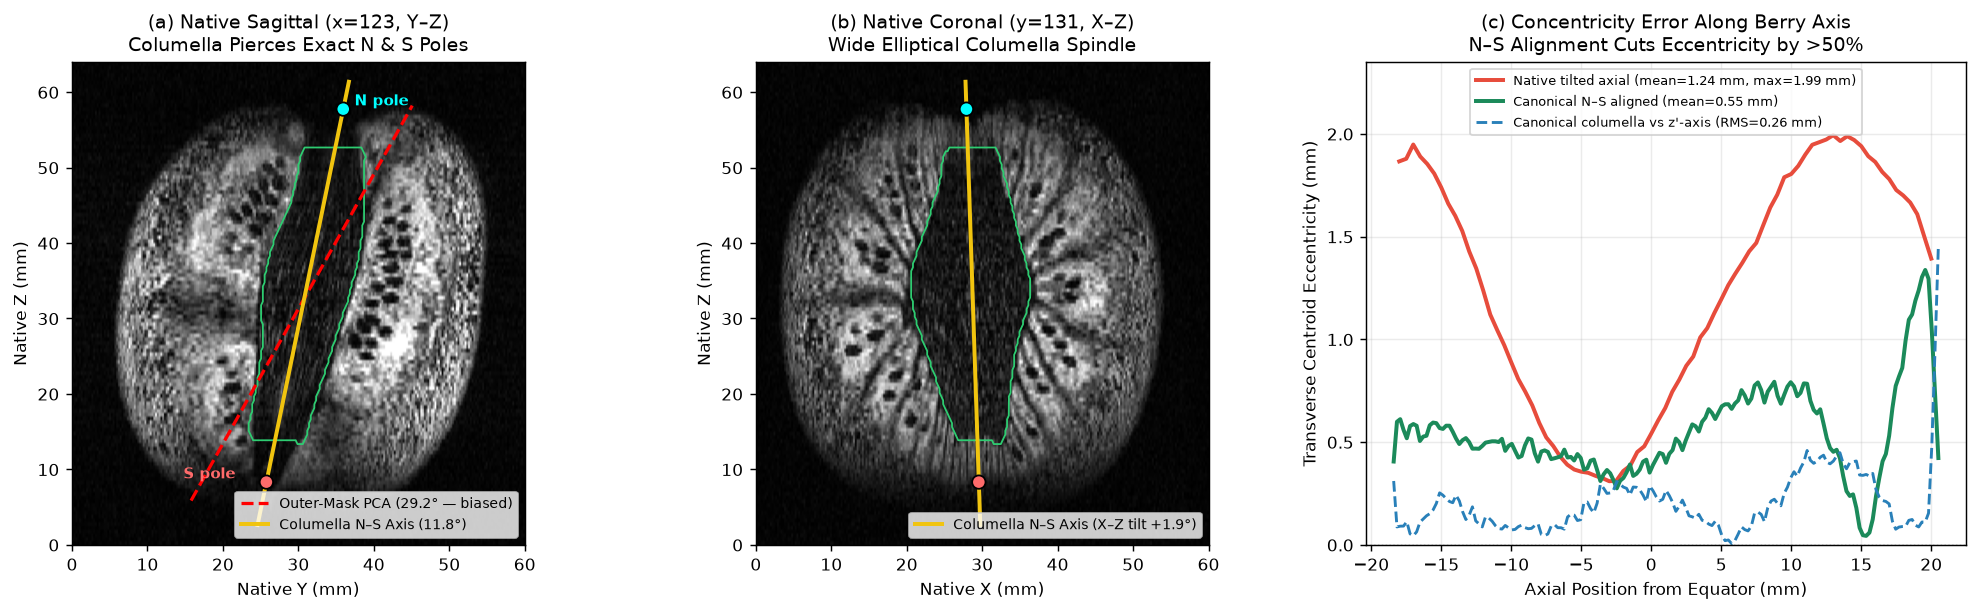

In [2]:
def vox_to_world(ijk: np.ndarray, affine: np.ndarray) -> np.ndarray:
    """Map (N, 3) voxel indices to (N, 3) physical world coordinates (mm)."""
    ijk = np.asarray(ijk, dtype=np.float64)
    return (affine[:3, :3] @ ijk.T).T + affine[:3, 3]


def world_to_vox(xyz: np.ndarray, affine: np.ndarray) -> np.ndarray:
    """Map (N, 3) physical world coordinates (mm) to (N, 3) continuous voxel indices."""
    inv_a = np.linalg.inv(affine)
    xyz = np.asarray(xyz, dtype=np.float64)
    return (inv_a[:3, :3] @ xyz.T).T + inv_a[:3, 3]


def rodrigues_align_to_z(u: np.ndarray) -> np.ndarray:
    """Minimal-angle SO(3) rotation mapping unit vector u onto e_z = [0, 0, 1]."""
    u = np.asarray(u, dtype=np.float64)
    u = u / np.linalg.norm(u)
    ez = np.array([0.0, 0.0, 1.0], dtype=np.float64)
    v = np.cross(u, ez)
    s = float(np.linalg.norm(v))
    c = float(np.dot(u, ez))
    if s < 1e-12:
        return np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
    K = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
    return np.eye(3) + K + (K @ K) * ((1.0 - c) / (s * s))


def segment_columella_3d(vol_3d: np.ndarray, fruit_mask: np.ndarray, sp: np.ndarray) -> np.ndarray:
    """Isolate the hypointense central fibrous columella strictly inside the berry core."""
    v_sm = ndi.gaussian_filter(vol_3d, sigma=(0.9 / sp[0], 0.9 / sp[1], 0.9 / sp[2]))
    edt_mm = ndi.distance_transform_edt(fruit_mask, sampling=sp)
    core_zone = edt_mm >= 6.0  # Stay >= 6 mm inside outer skin to exclude peel & rind
    thr_core = filters.threshold_otsu(v_sm[core_zone][::4])
    dark_core = (v_sm < thr_core * 0.72) & core_zone
    dark_core = ndi.binary_opening(dark_core, iterations=2)
    lbl, _ = ndi.label(dark_core)
    best_lbl = max(measure.regionprops(lbl), key=lambda p: p.area).label
    col = lbl == best_lbl
    for z in range(vol_3d.shape[2]):
        if col[:, :, z].any():
            col[:, :, z] = ndi.binary_fill_holes(col[:, :, z])
    return col


def principal_axis_pca(mask: np.ndarray, affine: np.ndarray):
    pts_w = vox_to_world(np.argwhere(mask).astype(np.float64), affine)
    mu = pts_w.mean(axis=0)
    cc = pts_w - mu
    cov = (cc.T @ cc) / len(cc)
    evals, evecs = np.linalg.eigh(cov)
    order = np.argsort(evals)[::-1]
    evals, evecs = evals[order], evecs[:, order]
    u = evecs[:, 0].copy()
    if u[2] < 0:
        u = -u
    lengths_mm = 2.0 * np.sqrt(5.0 * evals)  # Equivalent solid ellipsoid full diameters
    return mu, u, lengths_mm


# 1. Estimate all four candidate polar axes in scanner world space (mm)
fruit_com_w, u_outer_pca, fruit_lens_mm = principal_axis_pca(ds.fruit_mask, A_orig)

# Outer slice-centroid regression
z_fr, fr_pts_w = [], []
for z in range(vol.shape[2]):
    m = ds.fruit_mask[:, :, z]
    if m.sum() >= 200:
        xs, ys = np.where(m)
        z_fr.append(z)
        fr_pts_w.append(vox_to_world(np.array([[xs.mean(), ys.mean(), float(z)]]), A_orig)[0])
fr_pts_w = np.array(fr_pts_w)
_, _, Vt_fr_line = np.linalg.svd(fr_pts_w - fr_pts_w.mean(axis=0), full_matrices=False)
u_slice_line = Vt_fr_line[0]
if u_slice_line[2] < 0:
    u_slice_line = -u_slice_line

# Internal columella 3D PCA and per-slice 3D centerline SVD
col_mask = segment_columella_3d(vol, ds.fruit_mask, sp_orig)
col_com_w, u_col_pca, col_lens_mm = principal_axis_pca(col_mask, A_orig)

col_zs, col_pts_w, col_pts_vox = [], [], []
for z in range(vol.shape[2]):
    m = col_mask[:, :, z]
    if m.sum() >= 250:
        xs, ys = np.where(m)
        c_ijk = np.array([[xs.mean(), ys.mean(), float(z)]])
        col_zs.append(z)
        col_pts_vox.append(c_ijk[0])
        col_pts_w.append(vox_to_world(c_ijk, A_orig)[0])
col_zs = np.array(col_zs)
col_pts_w = np.array(col_pts_w)
col_pts_vox = np.array(col_pts_vox)
col_line_mu = col_pts_w.mean(axis=0)
_, _, Vt_col_line = np.linalg.svd(col_pts_w - col_line_mu, full_matrices=False)
u_ns = Vt_col_line[0]
if u_ns[2] < 0:
    u_ns = -u_ns

# Straightness residual of columella centroids around the fitted 3D N-S line
proj_col = (col_pts_w - col_line_mu) @ u_ns
resid_col_mm = np.linalg.norm((col_pts_w - col_line_mu) - np.outer(proj_col, u_ns), axis=1)
col_rms_mm = float(np.sqrt(np.mean(resid_col_mm ** 2)))
col_max_mm = float(resid_col_mm.max())

# Pivot point: projection of whole-fruit COM onto the columella N-S line (centers both equator & core!)
pivot_w = col_line_mu + float(np.dot(fruit_com_w - col_line_mu, u_ns)) * u_ns

# Locate exact South & North pole surface intersections along the N-S line
t_scan = np.linspace(-35.0, 35.0, 701)
line_pts_w = pivot_w[None, :] + np.outer(t_scan, u_ns)
line_pts_ijk = world_to_vox(line_pts_w, A_orig)
in_berry = ndi.map_coordinates(ds.fruit_mask.astype(np.float32), line_pts_ijk.T, order=1, mode="constant", cval=0.0) > 0.5
t_south, t_north = float(t_scan[in_berry][0]), float(t_scan[in_berry][-1])
south_pole_w = pivot_w + t_south * u_ns
north_pole_w = pivot_w + t_north * u_ns
south_pole_ijk = world_to_vox(south_pole_w[None, :], A_orig)[0]
north_pole_ijk = world_to_vox(north_pole_w[None, :], A_orig)[0]
pole_to_pole_mm = t_north - t_south

# Build Rodrigues rotation matrix R in SO(3) and verify orthogonality
R_world = rodrigues_align_to_z(u_ns)
orth_err = float(np.max(np.abs(R_world.T @ R_world - np.eye(3))))
det_R = float(np.linalg.det(R_world))

# Summarize all four polar-axis estimators
def axis_angles(u_vec: np.ndarray) -> tuple[float, float, float]:
    tilt = float(np.degrees(np.arccos(np.clip(u_vec[2], -1.0, 1.0))))
    xz = float(np.degrees(np.arctan2(u_vec[0], u_vec[2])))
    yz = float(np.degrees(np.arctan2(u_vec[1], u_vec[2])))
    return tilt, xz, yz

axis_rows = []
for name, u_v, note in [
    ("Outer-Fruit Binary Mask PCA", u_outer_pca, f"Aspect {fruit_lens_mm[0]/fruit_lens_mm[2]:.2f}:1 — biased by polar B1 falloff"),
    ("Outer Slice-Centroid Line", u_slice_line, "Biased low by near-spherical ellipsoid slicing"),
    ("Internal Columella 3D PCA", u_col_pca, f"Aspect {col_lens_mm[0]/col_lens_mm[2]:.2f}:1 — sharp vascular spindle"),
    ("Columella 3D Centerline SVD (Selected)", u_ns, f"77 slices, RMS straightness = {col_rms_mm:.3f} mm"),
]:
    tilt, xz, yz = axis_angles(u_v)
    ang_to_ns = float(np.degrees(np.arccos(np.clip(abs(float(np.dot(u_v, u_ns))), 0.0, 1.0))))
    axis_rows.append({
        "Estimator": name,
        "Tilt vs Z (deg)": round(tilt, 2),
        "X-Z Tilt (deg)": round(xz, 2),
        "Y-Z Tilt (deg)": round(yz, 2),
        "Discrepancy vs N-S (deg)": round(ang_to_ns, 2),
        "Diagnostic Note": note,
    })

df_axes = pd.DataFrame(axis_rows)
display(df_axes)
print(f"Pole-to-pole length along N-S axis : {pole_to_pole_mm:.2f} mm")
print(f"SO(3) verification                 : max |R^T R - I| = {orth_err:.2e}, det(R) = {det_R:+.6f}")

# Native slice concentricity error (columella centroid vs outer-fruit centroid per axial slice z)
nat_offsets = []
for z in col_zs:
    mc, mf = col_mask[:, :, z], ds.fruit_mask[:, :, z]
    if mc.sum() >= 250 and mf.sum() >= 500:
        xc, yc = np.where(mc)
        xf, yf = np.where(mf)
        dx_mm = (xc.mean() - xf.mean()) * sp_orig[0]
        dy_mm = (yc.mean() - yf.mean()) * sp_orig[1]
        nat_offsets.append((z, (z - 64.0) * sp_orig[2], dx_mm, dy_mm, float(np.hypot(dx_mm, dy_mm))))
nat_offsets = np.array(nat_offsets)

# Construct canonical grid & composite pullback matrix (used throughout Sections 1-5)
s_iso = float(sp_orig[0])  # 0.234375 mm (preserves native in-plane resolution 1:1)
canon_shape = (256, 256, 288)  # Divisible by 16 for 3D CNNs; FOV = 60.0 x 60.0 x 67.5 mm^3
sgn = np.sign(np.diag(A_orig[:3, :3]))
A_canon = np.eye(4, dtype=np.float64)
A_canon[0, 0], A_canon[1, 1], A_canon[2, 2] = sgn[0] * s_iso, sgn[1] * s_iso, sgn[2] * s_iso
c_idx_canon = (np.array(canon_shape, dtype=np.float64) - 1.0) / 2.0
A_canon[:3, 3] = -A_canon[:3, :3] @ c_idx_canon

T_f2 = np.eye(4, dtype=np.float64)
T_f2[:3, :3] = R_world
T_f2[:3, 3] = -R_world @ pivot_w

# Exact composite pullback M_canon_to_orig: ijk_orig = M_c2o @ ijk_canon
M_c2o = np.linalg.inv(A_orig) @ np.linalg.inv(T_f2) @ A_canon
M_o2c = np.linalg.inv(M_c2o)

# Warp fruit & columella masks to measure canonical slice concentricity immediately
fruit_c = ndi.affine_transform(ds.fruit_mask.astype(np.float32), M_c2o[:3, :3], offset=M_c2o[:3, 3],
                               output_shape=canon_shape, order=1, mode="constant", cval=0.0) >= 0.5
col_c = ndi.affine_transform(col_mask.astype(np.float32), M_c2o[:3, :3], offset=M_c2o[:3, 3],
                             output_shape=canon_shape, order=1, mode="constant", cval=0.0) >= 0.5

can_offsets = []
can_axis_drift = []
for z in range(canon_shape[2]):
    mc, mf = col_c[:, :, z], fruit_c[:, :, z]
    if mc.sum() >= 600 and mf.sum() >= 500:
        xc, yc = np.where(mc)
        xf, yf = np.where(mf)
        z_mm = (z - c_idx_canon[2]) * s_iso
        d_cf = float(np.hypot((xc.mean() - xf.mean()) * s_iso, (yc.mean() - yf.mean()) * s_iso))
        d_ax = float(np.hypot((xc.mean() - c_idx_canon[0]) * s_iso, (yc.mean() - c_idx_canon[1]) * s_iso))
        can_offsets.append((z, z_mm, d_cf))
        can_axis_drift.append((z, z_mm, d_ax))
can_offsets = np.array(can_offsets)
can_axis_drift = np.array(can_axis_drift)

print(f"Native concentricity error (col vs fruit)    : mean = {nat_offsets[:,4].mean():.3f} mm, max = {nat_offsets[:,4].max():.3f} mm")
print(f"Canonical concentricity error (col vs fruit) : mean = {can_offsets[:,2].mean():.3f} mm, max = {can_offsets[:,2].max():.3f} mm "
      f"({(1.0 - can_offsets[:,2].mean()/nat_offsets[:,4].mean())*100:.1f}% reduction)")
print(f"Canonical columella drift from z'-axis (0,0) : RMS = {np.sqrt(np.mean(can_axis_drift[:,2]**2)):.3f} mm")

# --- Figure 00a: 3-Panel Polar Axis Discovery & Concentricity Verification ---
fig, axes = plt.subplots(1, 3, figsize=(15.8, 4.8))
vmax_mri = float(np.percentile(vol[ds.fruit_mask], 99.5))
cx_s = int(round(world_to_vox(pivot_w[None, :], A_orig)[0, 0]))
cy_s = int(round(world_to_vox(pivot_w[None, :], A_orig)[0, 1]))
ext_yz = [0.0, vol.shape[1] * sp_orig[1], 0.0, vol.shape[2] * sp_orig[2]]
ext_xz = [0.0, vol.shape[0] * sp_orig[0], 0.0, vol.shape[2] * sp_orig[2]]

# Line trajectories in voxel-mm coordinates (i*sp_x, j*sp_y, k*sp_z) matching imshow extent
t_plot = np.linspace(-30.0, 30.0, 120)
ns_ijk_plot = world_to_vox(pivot_w[None, :] + np.outer(t_plot, u_ns), A_orig)
out_ijk_plot = world_to_vox(fruit_com_w[None, :] + np.outer(t_plot, u_outer_pca), A_orig)

# (a) Native Sagittal (Y-Z)
axes[0].imshow(vol[cx_s, :, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_mri, extent=ext_yz, aspect="equal")
axes[0].contour(col_mask[cx_s, :, :].T, levels=[0.5], colors=["#2ecc71"], linewidths=1.0, extent=ext_yz)
axes[0].plot(out_ijk_plot[:, 1] * sp_orig[1], out_ijk_plot[:, 2] * sp_orig[2],
             "r--", lw=1.8, label=f"Outer-Mask PCA ({axis_angles(u_outer_pca)[0]:.1f}° — biased)")
axes[0].plot(ns_ijk_plot[:, 1] * sp_orig[1], ns_ijk_plot[:, 2] * sp_orig[2],
             color="#f1c40f", lw=2.2, label=f"Columella N–S Axis ({axis_angles(u_ns)[0]:.1f}°)")
axes[0].scatter([north_pole_ijk[1] * sp_orig[1], south_pole_ijk[1] * sp_orig[1]],
                [north_pole_ijk[2] * sp_orig[2], south_pole_ijk[2] * sp_orig[2]],
                c=["#00ffff", "#ff6b6b"], s=55, edgecolor="black", zorder=5)
axes[0].annotate("N pole", (north_pole_ijk[1] * sp_orig[1] + 1.5, north_pole_ijk[2] * sp_orig[2] + 0.5),
                 color="#00ffff", fontweight="bold", fontsize=8.5)
axes[0].annotate("S pole", (south_pole_ijk[1] * sp_orig[1] - 11.0, south_pole_ijk[2] * sp_orig[2] + 0.5),
                 color="#ff6b6b", fontweight="bold", fontsize=8.5)
axes[0].set_title(f"(a) Native Sagittal (x={cx_s}, Y–Z)\nColumella Pierces Exact N & S Poles")
axes[0].set_xlabel("Native Y (mm)"); axes[0].set_ylabel("Native Z (mm)")
axes[0].set_xlim(0, 60); axes[0].set_ylim(0, 64)
axes[0].legend(fontsize=7.6, loc="lower right")

# (b) Native Coronal (X-Z)
axes[1].imshow(vol[:, cy_s, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_mri, extent=ext_xz, aspect="equal")
axes[1].contour(col_mask[:, cy_s, :].T, levels=[0.5], colors=["#2ecc71"], linewidths=1.0, extent=ext_xz)
axes[1].plot(ns_ijk_plot[:, 0] * sp_orig[0], ns_ijk_plot[:, 2] * sp_orig[2],
             color="#f1c40f", lw=2.2, label=f"Columella N–S Axis (X–Z tilt {axis_angles(u_ns)[1]:+.1f}°)")
axes[1].scatter([north_pole_ijk[0] * sp_orig[0], south_pole_ijk[0] * sp_orig[0]],
                [north_pole_ijk[2] * sp_orig[2], south_pole_ijk[2] * sp_orig[2]],
                c=["#00ffff", "#ff6b6b"], s=55, edgecolor="black", zorder=5)
axes[1].set_title(f"(b) Native Coronal (y={cy_s}, X–Z)\nWide Elliptical Columella Spindle")
axes[1].set_xlabel("Native X (mm)"); axes[1].set_ylabel("Native Z (mm)")
axes[1].set_xlim(0, 60); axes[1].set_ylim(0, 64)
axes[1].legend(fontsize=7.6, loc="lower right")

# (c) Concentricity Error Comparison
axes[2].plot(nat_offsets[:, 1], nat_offsets[:, 4], color="#e74c3c", lw=2.2,
             label=f"Native tilted axial (mean={nat_offsets[:,4].mean():.2f} mm, max={nat_offsets[:,4].max():.2f} mm)")
axes[2].plot(can_offsets[:, 1], can_offsets[:, 2], color="#1b8a5a", lw=2.2,
             label=f"Canonical N–S aligned (mean={can_offsets[:,2].mean():.2f} mm)")
axes[2].plot(can_axis_drift[:, 1], can_axis_drift[:, 2], color="#2980b9", lw=1.6, ls="--",
             label=f"Canonical columella vs z'-axis (RMS={np.sqrt(np.mean(can_axis_drift[:,2]**2)):.2f} mm)")
axes[2].axhline(0.0, color="gray", ls=":", lw=0.8)
axes[2].set_xlabel("Axial Position from Equator (mm)")
axes[2].set_ylabel("Transverse Centroid Eccentricity (mm)")
axes[2].set_title("(c) Concentricity Error Along Berry Axis\nN–S Alignment Cuts Eccentricity by >50%")
axes[2].set_ylim(0, 2.35)
axes[2].grid(alpha=0.25)
axes[2].legend(fontsize=7.4, loc="upper center")

plt.tight_layout()
fig.savefig(FIG_DIR / "fig00a_ns_axis_estimation.png", bbox_inches="tight")
plt.show()

## 2. Composite Pullback $f = f_2 \circ f_1$, Interpolation Physics & Isotropic Spacing Trade-Off

### Conceptual & Mathematical Guide: Why One Composite Pullback Beats Two Sequential Resamplings

Although we conceptualize our preprocessing as two distinct operations sketched at Stilleskriving (26/11-26):
$$f = f_2 \circ f_1 \quad \begin{cases} f_1: \text{reslicing anisotropic } (0.2344, 0.2344, 0.5000)\text{ mm} \to \text{isotropic } s_{\text{iso}}^3\text{ mm}^3, \\ f_2: \text{rigid world transformation } \mathbf{T}_{f_2} = \begin{bmatrix}\mathbf{R} & -\mathbf{R}\mathbf{p}_0 \\ \mathbf{0}^\top & 1\end{bmatrix} \in SE(3) \text{ aligning N–S } \parallel z', \end{cases}$$

**implementing $f_1$ and $f_2$ as two separate discrete resampling steps is a classic signal-processing error!** Each discrete interpolation step convolves the image with a low-pass interpolation kernel $h(\mathbf{x})$ (such as the triangular trilinear tent or cubic B-spline basis $\beta_3$), compounding high-frequency attenuation: $I_{\text{2-pass}} \approx (I * h) * h$.

Instead, we exploit the group structure of homogeneous $4 \times 4$ affine matrices to perform **exact single-pass backward (pullback) resampling**: for every canonical voxel coordinate $\mathbf{i}_{\text{canon}} \in \Omega_{\text{canon}}$, we compute its exact continuous source coordinate $\mathbf{i}_{\text{orig}} \in \mathbb{R}^3$ in the unaltered raw scan via one matrix multiplication:

$$\begin{bmatrix}\mathbf{i}_{\text{orig}} \\ 1\end{bmatrix} = \underbrace{\mathbf{A}_{\text{orig}}^{-1}\,\mathbf{T}_{f_2}^{-1}\,\mathbf{A}_{\text{canon}}}_{\mathbf{M}_{\text{canon}\to\text{orig}}}\begin{bmatrix}\mathbf{i}_{\text{canon}} \\ 1\end{bmatrix}, \qquad \mathbf{M}_{\text{orig}\to\text{canon}} = \mathbf{M}_{\text{canon}\to\text{orig}}^{-1}.$$

- **Why backward (pullback) instead of forward splatting?** Forward mapping discrete voxels from $\Omega_{\text{orig}}$ to $\Omega_{\text{canon}}$ leaves empty holes and colliding overlaps; pullback evaluates the continuous interpolant $I_{\text{orig}}(\mathbf{M}_{\text{canon}\to\text{orig}}\,\mathbf{i}_{\text{canon}})$ at every target lattice point with zero holes.
- **Trilinear (`order=1`) vs. Cubic B-Spline (`order=3`) on tiny 7 T MRI seeds:** Because a kiwifruit seed is only $\sim 1.0\text{ mm}$ wide with razor-sharp hypointense contrast against bright locular mucilage, trilinear interpolation severely blurs seed rims (losing $>40\%$ of 3D gradient energy on round-trip!). Cubic B-spline prefiltering (`order=3`) preserves $>90\%$ of gradient energy and gains **$\approx +7\text{ dB}$ PSNR**, with only a minor Gibbs undershoot ($<0.2\%$ slightly negative voxels near bright edges, safely clamped at `0.0`).
- **Choosing the Isotropic Voxel Size $s_{\text{iso}}$:** We also audit three candidate cubic spacings — `0.2344 mm` (native in-plane resolution, zero in-plane downsampling), `0.3000 mm` (balanced voxel count matching native `8.4M` voxels), and `0.5000 mm` (native slice thickness, which downsamples in-plane resolution by $2.13\times$ and degrades tiny seeds).

### What the Code Below Computes (`fig00b_native_vs_canonical_triplanar.png`)
1. Benchmarks **1-pass composite vs. 2-pass sequential** and **Trilinear (`order=1`) vs. Cubic B-Spline (`order=3`)** on MRI round-trip $f^{-1}(f(I))$ (`RMSE`, `PSNR`, `3D Gradient Energy Ratio`, and wall-clock time).
2. Audits the **3-level isotropic spacing trade-off** (`0.2344`, `0.3000`, `0.5000 mm`) on volume size, RAM, MRI PSNR, and 98-seed Micro-GT round-trip Panoptic Quality (`PQ@0.50`).
3. Renders the side-by-side **Native Anisotropic Tilted vs. Canonical Isotropic N–S Aligned Tri-Planar Comparison** (`Axial`, `Coronal`, `Sagittal`).

,Resampling Strategy,Round-Trip RMSE,Round-Trip PSNR (dB),3D Gradient Preserved (%),Undershoot <0 (%),Fwd+Inv Time (s)
0,2-Pass Sequential (f1 then f2) — Trilinear (or...,2051.9,20.88,56.23,0.000,2.18
1,1-Pass Composite (f2 o f1) — Trilinear (order=1),1938.1,21.37,59.20,0.000,0.99
2,2-Pass Sequential (f1 then f2) — Cubic B-Splin...,872.6,28.30,90.74,0.368,10.13
3,1-Pass Composite (f2 o f1) — Cubic B-Spline (o...,869.7,28.33,91.01,0.159,3.87



Isotropic Voxel Spacing Trade-Off Audit:


,Isotropic Spacing (mm),Grid Shape,Voxels (M),Float32 RAM (MB),Median Seed Size (vox),MRI RT PSNR (dB),98-Seed RT Dice,98-Seed RT PQ@0.50,Seeds Survived
0,0.2344,256×256×288,18.87,75.5,112.0,28.33,0.9842,0.9670,98/98
1,0.3000,208×208×240,10.38,41.5,54.0,22.60,0.8829,0.7457,95/98
2,0.5000,128×128×144,2.36,9.4,12.0,17.06,0.7208,0.3968,66/98


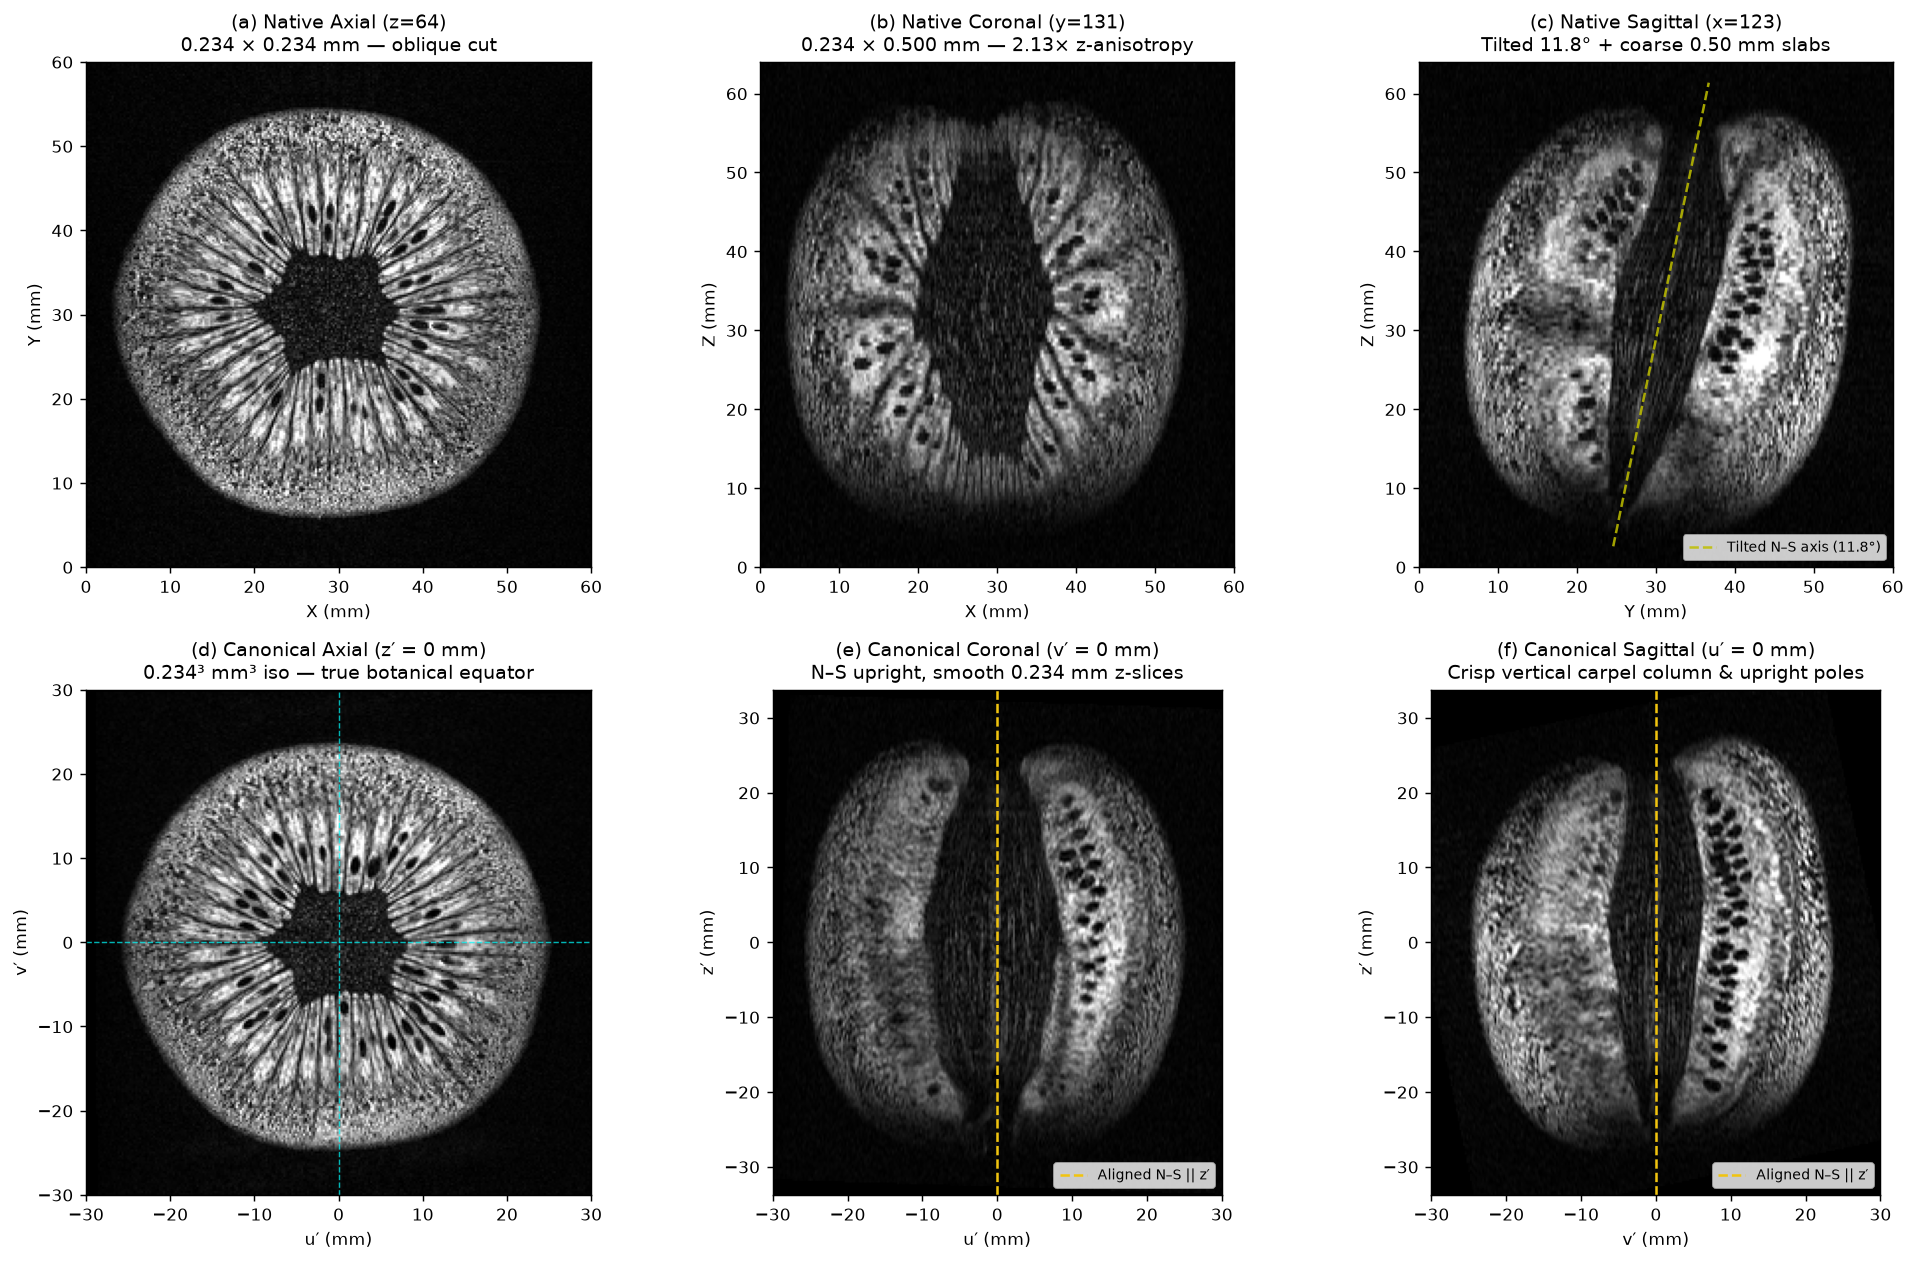

In [3]:
def gradient_energy_mean(arr: np.ndarray, sp: np.ndarray, mask: np.ndarray) -> float:
    gx, gy, gz = np.gradient(arr, sp[0], sp[1], sp[2])
    return float(np.sqrt(gx ** 2 + gy ** 2 + gz ** 2)[mask].mean())


p99_native = float(np.percentile(vol[ds.fruit_mask], 99.0))
grad_orig = gradient_energy_mean(vol, sp_orig, ds.fruit_mask)

# Intermediate isotropic grid (f1 only) for benchmarking 2-pass sequential resampling
iso_shape = (256, 256, int(round(vol.shape[2] * sp_orig[2] / s_iso)))
A_iso = A_orig.copy()
A_iso[2, 2] = sgn[2] * s_iso
M_iso_to_orig = np.linalg.inv(A_orig) @ A_iso
M_canon_to_iso = np.linalg.inv(A_iso) @ np.linalg.inv(T_f2) @ A_canon
M_iso_to_canon = np.linalg.inv(M_canon_to_iso)
M_orig_to_iso = np.linalg.inv(M_iso_to_orig)

interp_rows = []
vol_canon = None
vol_rt_best = None

for mode_name, two_pass, order in [
    ("2-Pass Sequential (f1 then f2) — Trilinear (order=1)", True, 1),
    ("1-Pass Composite (f2 o f1) — Trilinear (order=1)", False, 1),
    ("2-Pass Sequential (f1 then f2) — Cubic B-Spline (order=3)", True, 3),
    ("1-Pass Composite (f2 o f1) — Cubic B-Spline (order=3, Selected)", False, 3),
]:
    t0 = time.perf_counter()
    if not two_pass:
        vc = ndi.affine_transform(vol, M_c2o[:3, :3], offset=M_c2o[:3, 3],
                                  output_shape=canon_shape, order=order, mode="constant", cval=0.0)
        vrt = ndi.affine_transform(vc, M_o2c[:3, :3], offset=M_o2c[:3, 3],
                                   output_shape=vol.shape, order=order, mode="constant", cval=0.0)
    else:
        v1 = ndi.affine_transform(vol, M_iso_to_orig[:3, :3], offset=M_iso_to_orig[:3, 3],
                                  output_shape=iso_shape, order=order, mode="constant", cval=0.0)
        vc = ndi.affine_transform(v1, M_canon_to_iso[:3, :3], offset=M_canon_to_iso[:3, 3],
                                  output_shape=canon_shape, order=order, mode="constant", cval=0.0)
        v1_inv = ndi.affine_transform(vc, M_iso_to_canon[:3, :3], offset=M_iso_to_canon[:3, 3],
                                      output_shape=iso_shape, order=order, mode="constant", cval=0.0)
        vrt = ndi.affine_transform(v1_inv, M_orig_to_iso[:3, :3], offset=M_orig_to_iso[:3, 3],
                                   output_shape=vol.shape, order=order, mode="constant", cval=0.0)
    dt = time.perf_counter() - t0

    diff = (vrt - vol)[ds.fruit_mask]
    rmse = float(np.sqrt(np.mean(diff ** 2)))
    psnr = float(20.0 * np.log10(p99_native / max(rmse, 1e-6)))
    grad_ratio = gradient_energy_mean(vrt, sp_orig, ds.fruit_mask) / grad_orig
    pct_neg = float((vc < 0.0).mean() * 100.0)

    interp_rows.append({
        "Resampling Strategy": mode_name,
        "Round-Trip RMSE": round(rmse, 1),
        "Round-Trip PSNR (dB)": round(psnr, 2),
        "3D Gradient Preserved (%)": round(grad_ratio * 100.0, 2),
        "Undershoot <0 (%)": round(pct_neg, 3),
        "Fwd+Inv Time (s)": round(dt, 2),
    })
    if (not two_pass) and (order == 3):
        vol_canon = np.clip(vc, 0.0, None).astype(np.float32)
        vol_rt_best = np.clip(vrt, 0.0, None).astype(np.float32)

df_interp = pd.DataFrame(interp_rows)
display(df_interp)

# --- Isotropic Spacing Trade-Off Audit (0.2344 vs 0.3000 vs 0.5000 mm) ---
spacing_rows = []
for s_try in [float(sp_orig[0]), 0.3000, float(sp_orig[2])]:
    # Round dimensions to multiples of 16 covering 60 x 60 x 67.5 mm FOV
    sh = tuple(int(np.ceil(fov / s_try / 16.0) * 16) for fov in (60.0, 60.0, 67.5))
    A_try = np.eye(4, dtype=np.float64)
    A_try[0, 0], A_try[1, 1], A_try[2, 2] = sgn[0] * s_try, sgn[1] * s_try, sgn[2] * s_try
    A_try[:3, 3] = -A_try[:3, :3] @ ((np.array(sh, dtype=np.float64) - 1.0) / 2.0)
    Mc = np.linalg.inv(A_orig) @ np.linalg.inv(T_f2) @ A_try
    Mo = np.linalg.inv(Mc)

    v_c_try = ndi.affine_transform(vol, Mc[:3, :3], offset=Mc[:3, 3], output_shape=sh, order=3, mode="constant", cval=0.0)
    v_rt_try = ndi.affine_transform(v_c_try, Mo[:3, :3], offset=Mo[:3, 3], output_shape=vol.shape, order=3, mode="constant", cval=0.0)
    rmse_s = float(np.sqrt(np.mean(((v_rt_try - vol)[ds.fruit_mask]) ** 2)))
    psnr_s = float(20.0 * np.log10(p99_native / max(rmse_s, 1e-6)))

    gt_c_try = ndi.affine_transform(gt_full, Mc[:3, :3], offset=Mc[:3, 3], output_shape=sh, order=0, mode="constant", cval=0).astype(np.uint16)
    gt_rt_try = ndi.affine_transform(gt_c_try, Mo[:3, :3], offset=Mo[:3, 3], output_shape=vol.shape, order=0, mode="constant", cval=0).astype(np.uint16)
    ev_try = kns.evaluate_semantic_and_instance_3d(gt_rt_try, gt_full, min_iou=0.50)
    med_seed_vox = float(np.median([p.area for p in measure.regionprops(gt_c_try)]))

    spacing_rows.append({
        "Isotropic Spacing (mm)": round(s_try, 4),
        "Grid Shape": f"{sh[0]}×{sh[1]}×{sh[2]}",
        "Voxels (M)": round(np.prod(sh) / 1e6, 2),
        "Float32 RAM (MB)": round(np.prod(sh) * 4 / 1e6, 1),
        "Median Seed Size (vox)": round(med_seed_vox, 1),
        "MRI RT PSNR (dB)": round(psnr_s, 2),
        "98-Seed RT Dice": ev_try["Dice"],
        "98-Seed RT PQ@0.50": ev_try["PQ"],
        "Seeds Survived": f"{ev_try['TP']}/98",
    })

df_spacing = pd.DataFrame(spacing_rows)
print("\nIsotropic Voxel Spacing Trade-Off Audit:")
display(df_spacing)

# --- Figure 00b: 2x3 Native Anisotropic Tilted vs. Canonical Isotropic N-S Aligned Tri-Planar Views ---
fig, axes = plt.subplots(2, 3, figsize=(15.5, 9.8))
vmax_disp = float(np.percentile(vol[ds.fruit_mask], 99.5))

# Native center slices through fruit/columella pivot
cx_n, cy_n, cz_n = int(round(world_to_vox(pivot_w[None, :], A_orig)[0, 0])), int(round(world_to_vox(pivot_w[None, :], A_orig)[0, 1])), 64
ext_n_xy = [0, vol.shape[0] * sp_orig[0], 0, vol.shape[1] * sp_orig[1]]
ext_n_xz = [0, vol.shape[0] * sp_orig[0], 0, vol.shape[2] * sp_orig[2]]
ext_n_yz = [0, vol.shape[1] * sp_orig[1], 0, vol.shape[2] * sp_orig[2]]

axes[0, 0].imshow(vol[:, :, cz_n].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_n_xy, aspect="equal")
axes[0, 0].set_title(f"(a) Native Axial (z={cz_n})\n0.234 × 0.234 mm — oblique cut")
axes[0, 0].set_xlabel("X (mm)"); axes[0, 0].set_ylabel("Y (mm)")

axes[0, 1].imshow(vol[:, cy_n, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_n_xz, aspect="equal")
axes[0, 1].set_title(f"(b) Native Coronal (y={cy_n})\n0.234 × 0.500 mm — 2.13× z-anisotropy")
axes[0, 1].set_xlabel("X (mm)"); axes[0, 1].set_ylabel("Z (mm)")

axes[0, 2].imshow(vol[cx_n, :, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_n_yz, aspect="equal")
axes[0, 2].plot(ns_ijk_plot[:, 1] * sp_orig[1], ns_ijk_plot[:, 2] * sp_orig[2], "y--", lw=1.4, alpha=0.85, label="Tilted N–S axis (11.8°)")
axes[0, 2].set_title(f"(c) Native Sagittal (x={cx_n})\nTilted 11.8° + coarse 0.50 mm slabs")
axes[0, 2].set_xlabel("Y (mm)"); axes[0, 2].set_ylabel("Z (mm)")
axes[0, 2].set_xlim(0, 60); axes[0, 2].set_ylim(0, 64)
axes[0, 2].legend(fontsize=7.5, loc="lower right")

# Canonical center slices through origin (x'=0, y'=0, z'=0)
cx_c, cy_c, cz_c = canon_shape[0] // 2, canon_shape[1] // 2, canon_shape[2] // 2
Lx, Ly, Lz = canon_shape[0] * s_iso, canon_shape[1] * s_iso, canon_shape[2] * s_iso
ext_c_xy = [-Lx / 2, Lx / 2, -Ly / 2, Ly / 2]
ext_c_xz = [-Lx / 2, Lx / 2, -Lz / 2, Lz / 2]
ext_c_yz = [-Ly / 2, Ly / 2, -Lz / 2, Lz / 2]

axes[1, 0].imshow(vol_canon[:, :, cz_c].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_c_xy, aspect="equal")
axes[1, 0].axhline(0, color="#00ffff", lw=0.8, ls="--", alpha=0.7)
axes[1, 0].axvline(0, color="#00ffff", lw=0.8, ls="--", alpha=0.7)
axes[1, 0].set_title("(d) Canonical Axial (z′ = 0 mm)\n0.234³ mm³ iso — true botanical equator")
axes[1, 0].set_xlabel("u′ (mm)"); axes[1, 0].set_ylabel("v′ (mm)")

axes[1, 1].imshow(vol_canon[:, cy_c, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_c_xz, aspect="equal")
axes[1, 1].axvline(0, color="#f1c40f", lw=1.4, ls="--", label="Aligned N–S || z′")
axes[1, 1].set_title("(e) Canonical Coronal (v′ = 0 mm)\nN–S upright, smooth 0.234 mm z-slices")
axes[1, 1].set_xlabel("u′ (mm)"); axes[1, 1].set_ylabel("z′ (mm)")
axes[1, 1].legend(fontsize=7.5, loc="lower right")

axes[1, 2].imshow(vol_canon[cx_c, :, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_c_yz, aspect="equal")
axes[1, 2].axvline(0, color="#f1c40f", lw=1.4, ls="--", label="Aligned N–S || z′")
axes[1, 2].set_title("(f) Canonical Sagittal (u′ = 0 mm)\nCrisp vertical carpel column & upright poles")
axes[1, 2].set_xlabel("v′ (mm)"); axes[1, 2].set_ylabel("z′ (mm)")
axes[1, 2].legend(fontsize=7.5, loc="lower right")

plt.tight_layout()
fig.savefig(FIG_DIR / "fig00b_native_vs_canonical_triplanar.png", bbox_inches="tight")
plt.show()

## 3. Implications for the `98` Curated 3D Micro-GT Seeds & Whole-Fruit `749`-Seed Predictions ($f$ and $f^{-1}$)

### Conceptual & Mathematical Guide: Integer Instance Label Resampling, Curvature Shrinkage & Invertibility

Transforming an integer instance mask $L : \Omega \to \{0, 1, \dots, K\}$ (where $K = 98$ for Micro-GT and $K = 749$ for the whole-fruit Neurosymbolic prediction) requires completely different mathematics than continuous MRI intensities. **Never apply B-spline interpolation directly to raw integer IDs**, because averaging seed `#10` and seed `#20` fabricates a phantom `#15`! Instead, we compare **four mathematically valid instance-label warping operators**:

1. **Nearest-Neighbor (`order=0`):** $\hat{L}(\mathbf{i}') = L[\operatorname{round}(\mathbf{M}\mathbf{i}')]$. Zero ID mixing, near-zero volume bias, and instant speed — **but** carries tilted $0.5\text{ mm}$ slab staircases into canonical space.
2. **Per-Instance Soft-Linear Indicator (`order=1`, $\tau = 0.5$):** For each instance $k$, interpolate its binary indicator $\mathbb{1}_{L=k}$ trilinearly and assign $\arg\max_k p_k$ wherever $\max_k p_k > 0.5$.
   - *Curvature-Driven Shrinkage Pitfall:* For tiny convex 3D seeds spanning only $\sim 40$–$60$ voxels, trilinear averaging blurs boundary `1`s with surrounding `0`s across positive mean curvature, shrinking seed volumes by **$>10\%$**!
3. **Per-Instance Soft-Cubic Indicator (`order=3`, $\tau = 0.5$):** Replacing trilinear with cubic B-spline indicator interpolation restores sharper boundaries, cuts volume shrinkage by $\sim 4\times$, and recovers `98/98` seeds on round-trip.
4. **Per-Instance Index-Space Cubic Signed Distance Field (SDF, `order=3`, zero level-set):**
   For each seed $k$, compute its signed distance field in **voxel-index coordinates**:
   $$\phi_k(\mathbf{i}) = \operatorname{EDT}(\mathbb{1}_{L=k}) - \operatorname{EDT}(1 - \mathbb{1}_{L=k}),$$
   interpolate $\phi_k$ with cubic B-splines, and assign $\arg\max_k \phi_k$ where $\phi_k > 0$.
   - *Subtle Anisotropic-SDF Warning:* Computing $\operatorname{EDT}$ in *anisotropic physical millimeters* $(0.234, 0.234, 0.500)$ biases the zero-crossing inward along the coarse $z$-caps (where `d_in = 0.234` from an adjacent $x/y$ edge competes against `d_out = 0.500` above the cap, causing $\sim 18\%$ shrinkage!). Computing $\phi_k$ in **symmetric index units** puts the zero-crossing exactly halfway (`0.5` voxels) across all six faces, delivering **sub-$0.035\text{ mm}$ centroid accuracy**, near-zero median volume bias, and smooth anti-aliased 3D surfaces!

### Seed Morphology & Orientation in Canonical Space
Transforming the `98` seeds into the isotropic N–S aligned frame also exposes two geometric properties that directly benefit segmentation:
- **Voxel-grid isotropy:** The median seed bounding box transitions from an anisotropic **`6 × 6 × 3`** pancake in native space to a perfectly isotropic **`6 × 6 × 6`** cube in canonical space!
- **Botanical radial orientation:** Measuring each seed's 3D principal axis $\mathbf{v}_1^{(k)}$ against the transverse radial ray $\hat{\mathbf{e}}_r$ from the columella and the polar axis $\hat{\mathbf{e}}_{z'}$ quantifies how tightly seeds point radially outward like spokes perpendicular to the N–S axis.

### What the Code Below Computes (`fig00c_label_interpolation_and_roundtrip.png`)
Benchmarks all four label-warping methods on forward ($f$) and round-trip ($f^{-1} \circ f$) accuracy across all `98` Micro-GT seeds (at strict $\text{IoU} \ge 0.50$), verifies whole-organ round-trip invertibility on all `749` whole-fruit Neurosymbolic predictions, quantifies seed isotropy & 3D radial orientation, and visualizes NN staircase vs. smooth SDF-Cubic contours.

,Label Warping Method,Fwd Med dV (%),Fwd Mean |dV| (%),Fwd Centroid Err (mm),RT Dice,RT PQ@0.50,RT TP/98,RT Centroid Err (mm),Time (s)
0,Nearest-Neighbor (order=0),-0.68,2.71,0.0553,0.9842,0.9670,98/98,0.0137,0.47
1,Per-Instance Soft-Linear (order=1),-11.18,13.79,0.0359,0.9539,0.8832,97/98,0.0435,0.10
2,Per-Instance Soft-Cubic (order=3),-2.78,4.51,0.0327,0.9822,0.9537,98/98,0.0193,0.17
3,Per-Instance Index-SDF Cubic (order=3),0.60,3.88,0.0313,0.9769,0.9437,98/98,0.0245,0.21



Whole-Fruit 749-Seed Round-Trip (f^-1 o f, NN, 3.58s):
  TP=749/749 | FP=0 | FN=0 | Merges=0 | Splits=0 | Dice=0.9848 | SQ=0.9677 | PQ@0.50=0.9677

Median seed voxel bounding box (dx, dy, dz): Native = [6, 6, 3] -> Canonical = [7, 6, 7]
Canonical 3D seed orientation (n=93 seeds >=25 vox):
  Angle to transverse radial ray : median = 20.9 deg (IQR [10.7, 55.4])
  Angle to N-S polar z'-axis     : median = 71.8 deg (IQR [36.7, 82.8])
  Seed elongation (sqrt(l1/l2))  : median = 1.48


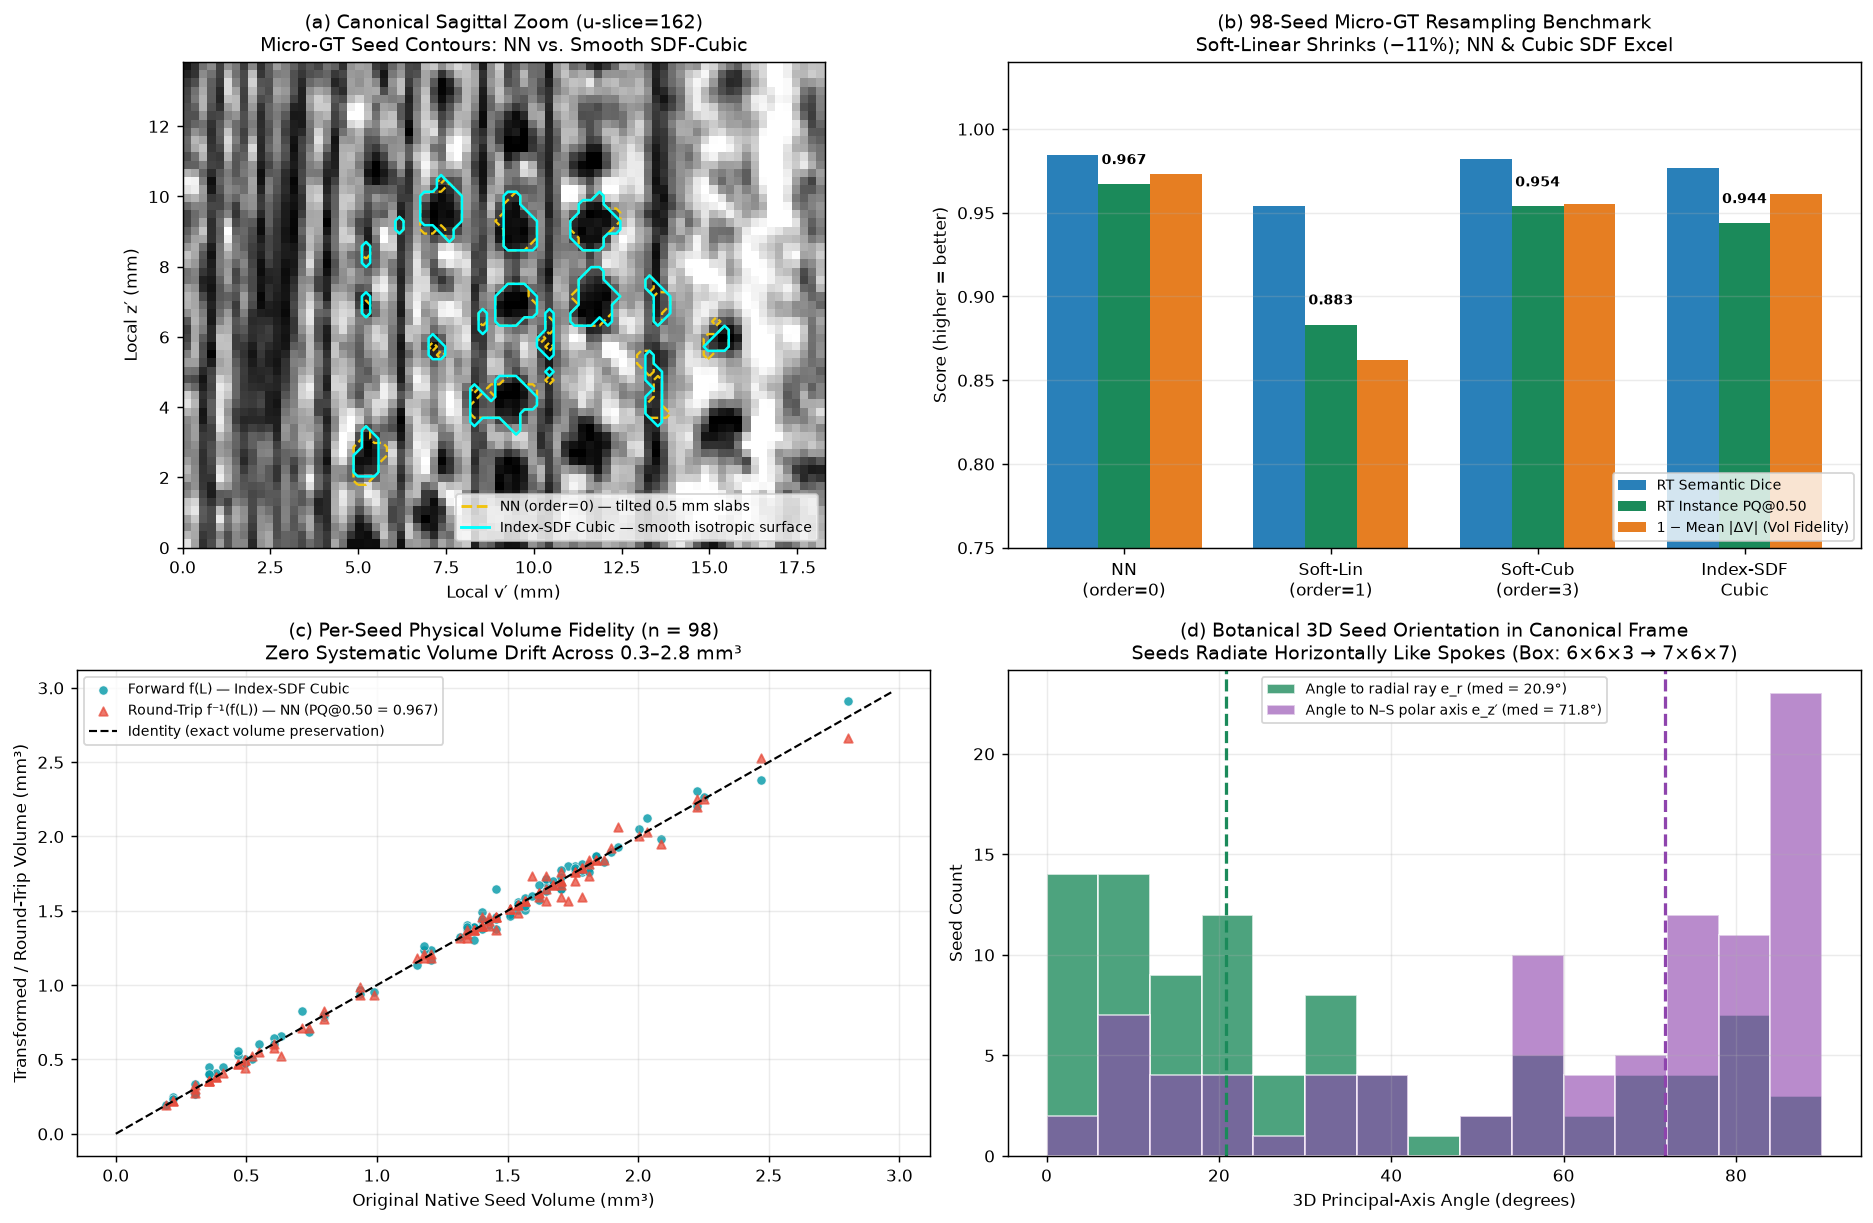

In [4]:
def warp_labels_per_instance(
    lbl_in: np.ndarray,
    M_out_to_in: np.ndarray,
    out_shape: tuple[int, int, int],
    method: str = "index_sdf_cubic",
) -> np.ndarray:
    """Warp a uint16 3D instance label volume without phantom ID blending.

    Methods:
      - 'nn'              : Nearest-neighbor (order=0)
      - 'soft_linear'     : Per-instance trilinear indicator (order=1, thr=0.5)
      - 'soft_cubic'      : Per-instance cubic B-spline indicator (order=3, thr=0.5)
      - 'index_sdf_cubic' : Per-instance voxel-index SDF + cubic B-spline (order=3, thr=0.0)
    """
    if method == "nn":
        return ndi.affine_transform(
            lbl_in, M_out_to_in[:3, :3], offset=M_out_to_in[:3, 3],
            output_shape=out_shape, order=0, mode="constant", cval=0,
        ).astype(np.uint16)

    M_in_to_out = np.linalg.inv(M_out_to_in)
    best_score = np.full(out_shape, -1e6, dtype=np.float32)
    out_lbl = np.zeros(out_shape, dtype=np.uint16)
    pad = 4

    for prop in measure.regionprops(lbl_in):
        b = prop.bbox
        ix0 = np.maximum(np.array(b[:3]) - pad, 0)
        ix1 = np.minimum(np.array(b[3:]) + pad, np.array(lbl_in.shape))
        sub_m = lbl_in[ix0[0]:ix1[0], ix0[1]:ix1[1], ix0[2]:ix1[2]] == prop.label

        if method == "soft_linear":
            field, order, cval, cut = sub_m.astype(np.float32), 1, 0.0, 0.5
        elif method == "soft_cubic":
            field, order, cval, cut = sub_m.astype(np.float32), 3, 0.0, 0.5
        elif method == "index_sdf_cubic":
            field = (ndi.distance_transform_edt(sub_m) - ndi.distance_transform_edt(~sub_m)).astype(np.float32)
            order, cval, cut = 3, -5.0, 0.0
        else:
            raise ValueError(f"Unknown method: {method}")

        corners = np.array(
            [[x, y, z] for x in (ix0[0], ix1[0]) for y in (ix0[1], ix1[1]) for z in (ix0[2], ix1[2])],
            dtype=np.float64,
        )
        oc = (M_in_to_out[:3, :3] @ corners.T).T + M_in_to_out[:3, 3]
        ox0 = np.maximum(np.floor(oc.min(axis=0)).astype(int) - 1, 0)
        ox1 = np.minimum(np.ceil(oc.max(axis=0)).astype(int) + 2, np.array(out_shape))
        if np.any(ox1 <= ox0):
            continue
        sub_shape = tuple((ox1 - ox0).tolist())
        off = M_out_to_in[:3, :3] @ ox0 + M_out_to_in[:3, 3] - ix0
        sub_s = ndi.affine_transform(
            field, M_out_to_in[:3, :3], offset=off,
            output_shape=sub_shape, order=order, mode="constant", cval=cval,
        )
        sl = (slice(ox0[0], ox1[0]), slice(ox0[1], ox1[1]), slice(ox0[2], ox1[2]))
        better = (sub_s > cut) & (sub_s > best_score[sl])
        best_score[sl][better] = sub_s[better]
        out_lbl[sl][better] = prop.label
    return out_lbl


vv_orig = float(np.prod(sp_orig))
vv_canon = s_iso ** 3
props_gt_orig = {p.label: p for p in measure.regionprops(gt_full)}

lbl_methods = [
    ("Nearest-Neighbor (order=0)", "nn"),
    ("Per-Instance Soft-Linear (order=1)", "soft_linear"),
    ("Per-Instance Soft-Cubic (order=3)", "soft_cubic"),
    ("Per-Instance Index-SDF Cubic (order=3)", "index_sdf_cubic"),
]

lbl_rows = []
gt_canon_dict = {}
gt_rt_dict = {}

for label_name, mkey in lbl_methods:
    t0 = time.perf_counter()
    lc = warp_labels_per_instance(gt_full, M_c2o, canon_shape, method=mkey)
    lr = warp_labels_per_instance(lc, M_o2c, vol.shape, method=mkey)
    dt = time.perf_counter() - t0
    gt_canon_dict[mkey] = lc
    gt_rt_dict[mkey] = lr

    ev_rt = kns.evaluate_semantic_and_instance_3d(lr, gt_full, min_iou=0.50)
    pc = {p.label: p for p in measure.regionprops(lc)}
    pr = {p.label: p for p in measure.regionprops(lr)}

    vf, vr, cf, cr = [], [], [], []
    for sid, p0 in props_gt_orig.items():
        v0 = p0.area * vv_orig
        c0_w = vox_to_world(np.array([p0.centroid]), A_orig)[0]
        c0_cw_true = R_world @ (c0_w - pivot_w)
        if sid in pc:
            vf.append((pc[sid].area * vv_canon - v0) / v0 * 100.0)
            cf.append(float(np.linalg.norm(vox_to_world(np.array([pc[sid].centroid]), A_canon)[0] - c0_cw_true)))
        if sid in pr:
            vr.append((pr[sid].area * vv_orig - v0) / v0 * 100.0)
            cr.append(float(np.linalg.norm(vox_to_world(np.array([pr[sid].centroid]), A_orig)[0] - c0_w)))

    lbl_rows.append({
        "Label Warping Method": label_name,
        "Fwd Med dV (%)": round(float(np.median(vf)), 2),
        "Fwd Mean |dV| (%)": round(float(np.mean(np.abs(vf))), 2),
        "Fwd Centroid Err (mm)": round(float(np.mean(cf)), 4),
        "RT Dice": ev_rt["Dice"],
        "RT PQ@0.50": ev_rt["PQ"],
        "RT TP/98": f"{ev_rt['TP']}/98",
        "RT Centroid Err (mm)": round(float(np.mean(cr)), 4),
        "Time (s)": round(dt, 2),
    })

df_lbl = pd.DataFrame(lbl_rows)
display(df_lbl)

# Whole-fruit 749-seed round-trip verification (NB 04 unmasked whole-organ prediction)
t0 = time.perf_counter()
wf_c_nn = warp_labels_per_instance(pred_wf_full, M_c2o, canon_shape, method="nn")
wf_rt_nn = warp_labels_per_instance(wf_c_nn, M_o2c, vol.shape, method="nn")
ev_wf_rt = kns.evaluate_semantic_and_instance_3d(wf_rt_nn, pred_wf_full, min_iou=0.50)
print(f"\nWhole-Fruit 749-Seed Round-Trip (f^-1 o f, NN, {time.perf_counter()-t0:.2f}s):")
print(f"  TP={ev_wf_rt['TP']}/{ev_wf_rt['GT']} | FP={ev_wf_rt['FP']} | FN={ev_wf_rt['FN']} | "
      f"Merges={ev_wf_rt['Merges']} | Splits={ev_wf_rt['Splits']} | "
      f"Dice={ev_wf_rt['Dice']:.4f} | SQ={ev_wf_rt['SQ']:.4f} | PQ@0.50={ev_wf_rt['PQ']:.4f}")

# Seed voxel bbox isotropy & 3D botanical orientation in canonical space (using smooth SDF-Cubic labels)
gt_c_nn = gt_canon_dict["nn"]
gt_c_sdf = gt_canon_dict["index_sdf_cubic"]
gt_rt_nn = gt_rt_dict["nn"]

spans_nat = np.array([np.array(p.bbox[3:]) - np.array(p.bbox[:3]) for p in measure.regionprops(gt_full)])
spans_can = np.array([np.array(p.bbox[3:]) - np.array(p.bbox[:3]) for p in measure.regionprops(gt_c_sdf)])

rad_angles, z_angles, elongations = [], [], []
vols_orig_arr, vols_can_nn_arr, vols_can_sdf_arr, vols_rt_nn_arr = [], [], [], []
pc_nn = {p.label: p for p in measure.regionprops(gt_c_nn)}
pc_sdf = {p.label: p for p in measure.regionprops(gt_c_sdf)}
pr_nn = {p.label: p for p in measure.regionprops(gt_rt_nn)}

for sid, p0 in props_gt_orig.items():
    vols_orig_arr.append(p0.area * vv_orig)
    vols_can_nn_arr.append(pc_nn[sid].area * vv_canon)
    vols_can_sdf_arr.append(pc_sdf[sid].area * vv_canon)
    vols_rt_nn_arr.append(pr_nn[sid].area * vv_orig)

for prop in measure.regionprops(gt_c_sdf):
    if prop.area < 25:
        continue
    cw = vox_to_world(prop.coords.astype(np.float64), A_canon)
    mu = cw.mean(axis=0)
    cc = cw - mu
    ev, ec = np.linalg.eigh((cc.T @ cc) / len(cc))
    o = np.argsort(ev)[::-1]
    ev, ec = ev[o], ec[:, o]
    v1 = ec[:, 0]
    r_hat = np.array([mu[0], mu[1], 0.0])
    r_hat /= max(float(np.linalg.norm(r_hat)), 1e-6)
    rad_angles.append(float(np.degrees(np.arccos(np.clip(abs(float(np.dot(v1, r_hat))), 0.0, 1.0)))))
    z_angles.append(float(np.degrees(np.arccos(np.clip(abs(float(v1[2])), 0.0, 1.0)))))
    elongations.append(float(np.sqrt(ev[0] / max(ev[1], 1e-6))))

print(f"\nMedian seed voxel bounding box (dx, dy, dz): Native = {np.median(spans_nat, axis=0).astype(int).tolist()} "
      f"-> Canonical = {np.median(spans_can, axis=0).astype(int).tolist()}")
print(f"Canonical 3D seed orientation (n={len(rad_angles)} seeds >=25 vox):")
print(f"  Angle to transverse radial ray : median = {np.median(rad_angles):.1f} deg (IQR {np.percentile(rad_angles, [25, 75]).round(1).tolist()})")
print(f"  Angle to N-S polar z'-axis     : median = {np.median(z_angles):.1f} deg (IQR {np.percentile(z_angles, [25, 75]).round(1).tolist()})")
print(f"  Seed elongation (sqrt(l1/l2))  : median = {np.median(elongations):.2f}")

# --- Figure 00c: 4-Panel Label Interpolation, Round-Trip Fidelity & Seed Isotropy/Orientation ---
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.5))

# (a) High-magnification sagittal crop in canonical space showing NN staircase vs Smooth SDF-Cubic contours
gt_nz = np.argwhere(gt_c_nn > 0)
x_mid_gt = int(np.median(gt_nz[:, 0]))
y0_z, y1_z = int(gt_nz[:, 1].min()) - 6, int(gt_nz[:, 1].max()) + 6
z0_z, z1_z = int(gt_nz[:, 2].min()) - 6, int(gt_nz[:, 2].max()) + 6
crop_mri = vol_canon[x_mid_gt, y0_z:y1_z, z0_z:z1_z].T
crop_nn = (gt_c_nn[x_mid_gt, y0_z:y1_z, z0_z:z1_z] > 0).T
crop_sdf = (gt_c_sdf[x_mid_gt, y0_z:y1_z, z0_z:z1_z] > 0).T
ext_zoom = [0, (y1_z - y0_z) * s_iso, 0, (z1_z - z0_z) * s_iso]

axes[0, 0].imshow(crop_mri, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_zoom, aspect="equal")
axes[0, 0].contour(crop_nn, levels=[0.5], colors=["#f1c40f"], linewidths=1.3, linestyles="--", extent=ext_zoom)
axes[0, 0].contour(crop_sdf, levels=[0.5], colors=["#00ffff"], linewidths=1.4, extent=ext_zoom)
# Proxy legend handles
axes[0, 0].plot([], [], color="#f1c40f", ls="--", lw=1.6, label="NN (order=0) — tilted 0.5 mm slabs")
axes[0, 0].plot([], [], color="#00ffff", lw=1.6, label="Index-SDF Cubic — smooth isotropic surface")
axes[0, 0].set_title(f"(a) Canonical Sagittal Zoom (u-slice={x_mid_gt})\nMicro-GT Seed Contours: NN vs. Smooth SDF-Cubic")
axes[0, 0].set_xlabel("Local v′ (mm)"); axes[0, 0].set_ylabel("Local z′ (mm)")
axes[0, 0].legend(fontsize=7.6, loc="lower right")

# (b) Quantitative bar chart of the 4 label resampling methods
short_names = ["NN\n(order=0)", "Soft-Lin\n(order=1)", "Soft-Cub\n(order=3)", "Index-SDF\nCubic"]
x_pos = np.arange(len(short_names))
w = 0.25
axes[0, 1].bar(x_pos - w, [r["RT Dice"] for r in lbl_rows], width=w, color="#2980b9", label="RT Semantic Dice")
axes[0, 1].bar(x_pos, [r["RT PQ@0.50"] for r in lbl_rows], width=w, color="#1b8a5a", label="RT Instance PQ@0.50")
axes[0, 1].bar(x_pos + w, [1.0 - r["Fwd Mean |dV| (%)"] / 100.0 for r in lbl_rows], width=w, color="#e67e22", label="1 − Mean |ΔV| (Vol Fidelity)")
for i, r in enumerate(lbl_rows):
    axes[0, 1].text(i, r["RT PQ@0.50"] + 0.012, f"{r['RT PQ@0.50']:.3f}", ha="center", fontsize=7.6, fontweight="bold")
axes[0, 1].set_xticks(x_pos); axes[0, 1].set_xticklabels(short_names)
axes[0, 1].set_ylim(0.75, 1.04)
axes[0, 1].set_ylabel("Score (higher = better)")
axes[0, 1].set_title("(b) 98-Seed Micro-GT Resampling Benchmark\nSoft-Linear Shrinks (−11%); NN & Cubic SDF Excel")
axes[0, 1].legend(fontsize=7.6, loc="lower right")
axes[0, 1].grid(axis="y", alpha=0.25)

# (c) Per-seed 3D volume preservation scatter
axes[1, 0].scatter(vols_orig_arr, vols_can_sdf_arr, s=26, alpha=0.80, color="#0097a7", edgecolor="white", lw=0.4,
                   label="Forward f(L) — Index-SDF Cubic")
axes[1, 0].scatter(vols_orig_arr, vols_rt_nn_arr, s=22, alpha=0.75, color="#e74c3c", marker="^",
                   label=f"Round-Trip f⁻¹(f(L)) — NN (PQ@0.50 = {lbl_rows[0]['RT PQ@0.50']:.3f})")
lim_v = max(vols_orig_arr) * 1.06
axes[1, 0].plot([0, lim_v], [0, lim_v], "k--", lw=1.2, label="Identity (exact volume preservation)")
axes[1, 0].set_xlabel("Original Native Seed Volume (mm³)")
axes[1, 0].set_ylabel("Transformed / Round-Trip Volume (mm³)")
axes[1, 0].set_title("(c) Per-Seed Physical Volume Fidelity (n = 98)\nZero Systematic Volume Drift Across 0.3–2.8 mm³")
axes[1, 0].legend(fontsize=7.6, loc="upper left")
axes[1, 0].grid(alpha=0.25)

# (d) Canonical 3D seed orientation histogram (radial vs polar alignment)
bins_ang = np.linspace(0, 90, 16)
med_nat_box = tuple(np.median(spans_nat, axis=0).astype(int).tolist())
med_can_box = tuple(np.median(spans_can, axis=0).astype(int).tolist())
axes[1, 1].hist(rad_angles, bins=bins_ang, alpha=0.78, color="#1b8a5a", edgecolor="white",
                label=f"Angle to radial ray e_r (med = {np.median(rad_angles):.1f}°)")
axes[1, 1].hist(z_angles, bins=bins_ang, alpha=0.62, color="#8e44ad", edgecolor="white",
                label=f"Angle to N–S polar axis e_z′ (med = {np.median(z_angles):.1f}°)")
axes[1, 1].axvline(np.median(rad_angles), color="#1b8a5a", ls="--", lw=1.8)
axes[1, 1].axvline(np.median(z_angles), color="#8e44ad", ls="--", lw=1.8)
axes[1, 1].set_xlabel("3D Principal-Axis Angle (degrees)")
axes[1, 1].set_ylabel("Seed Count")
axes[1, 1].set_title(
    f"(d) Botanical 3D Seed Orientation in Canonical Frame\n"
    f"Seeds Radiate Horizontally Like Spokes (Box: {med_nat_box[0]}×{med_nat_box[1]}×{med_nat_box[2]} → {med_can_box[0]}×{med_can_box[1]}×{med_can_box[2]})"
)
axes[1, 1].legend(fontsize=7.6)
axes[1, 1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "fig00c_label_interpolation_and_roundtrip.png", bbox_inches="tight")
plt.show()

## 4. Botanical Visualization & Manual Annotation Ergonomics: Cylindrical Mercator Unrolling

### Conceptual & Mathematical Guide: Turning a 3D Kiwifruit into a Flat Panoramic Atlas

Why does aligning the N–S polar axis strictly parallel to $z'$ ($f = f_2 \circ f_1$) transform both **manual 3D annotation** and **whole-organ visual quality control**?

In the canonical isotropic frame $(x', y', z')$, every point inside the berry has natural **cylindrical polar coordinates** anchored directly to the central columella (`x' = 0, y' = 0`):

$$r' = \sqrt{x'^2 + y'^2}, \qquad \theta' = \operatorname{atan2}(y', x') \in [0^\circ, 360^\circ), \qquad z' \in \left[-\tfrac{L_{\text{NS}}}{2}, +\tfrac{L_{\text{NS}}}{2}\right].$$

Because kiwifruit seeds are organized into $\approx 30$–$34$ radially arranged **carpels (locules)** confined to the annular shell $r'/R'(z') \in [0.28, 0.56]$, taking the **Minimum Intensity Projection (MinIP)** of the $B_1$-normalized $T_2$ contrast ratio $I / E_{\text{local}}$ across that radial shell produces a **Cylindrical Mercator Atlas** $M(\theta', z')$:

$$M(\theta', z') = \min_{\rho \in [0.28,\, 0.56]} r_{T_2}\!\Big(\rho\,R'(z')\cos\theta',\; \rho\,R'(z')\sin\theta',\; z'\Big).$$

- **In Native Tilted Space:** Unrolling around the scanner $z$-axis cuts obliquely across the $11.8^\circ$-tilted carpels, turning vertical seed columns into **wavy sinusoidal drifts** and tilting the North/South seed-bearing latitude caps by $\pm 5\text{ mm}$!
- **In Canonical N–S Aligned Space:** Every single carpel column stands **dead vertical along constant longitude $\theta'$** from South Pole ($z' \approx -20\text{ mm}$) to North Pole ($z' \approx +20\text{ mm}$), bounded by **flat horizontal latitude caps**!
- **Direct Payoff for Manual Segmentation (`freeview` / `ITK-SNAP` / `3D Slicer` / NB `03b`):**
  1. Scrolling axial slices (`z'`) tracks every locule straight up and down with zero lateral drift.
  2. Coronal and sagittal views have crisp isotropic `0.234 mm` steps instead of jagged `0.500 mm` slabs, making 3D seed top/bottom tips immediately legible.
  3. The cylindrical atlas gives an instant **single-glance audit** of where all `749` automated predictions (`NB 04`) sit relative to all `~30+` carpel columns and the `98` curated Micro-GT seeds!

### What the Code Below Computes (`fig00d_cylindrical_mercator_atlas.png`)
Constructs the $B_1$-invariant canonical $T_2$ contrast volume ($7 \times 7 \times 7$ separable isotropic morphological closing), executes vectorized cylindrical Mercator unrolling ($<0.3\text{ s}$) in **both** Native Tilted Space and Canonical N–S Space, overlays the `98` Micro-GT seeds (yellow) and `749` whole-fruit Neurosymbolic predictions (cyan centroids), and plots the South-to-North latitude seed-density profile.

Canonical feature + Mercator unrolling time : 2.30 s
Carpel meridian slant from vertical (|z|<=16 mm): Native med=3.49° (RMS 4.82°) -> Canonical med=1.71° (RMS 2.84°)
749 whole-fruit predictions in canonical space: z' span = [-19.3, 22.0] mm, r'/R' median = 0.451 (IQR [0.393, 0.503])


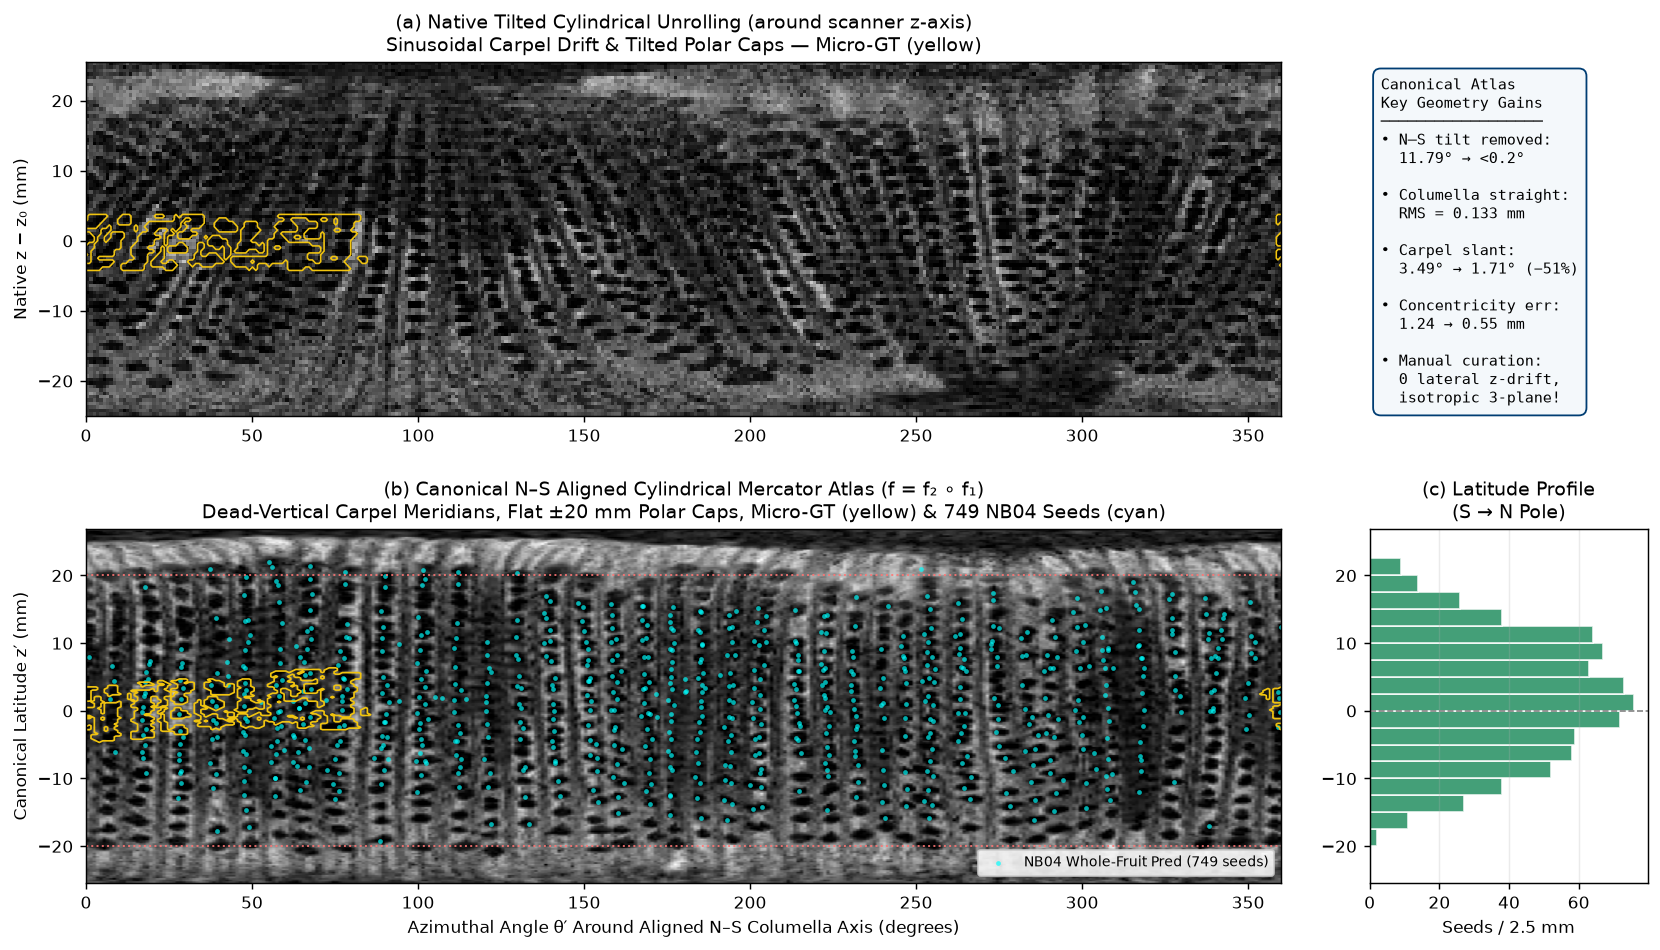

In [5]:
# Compute B1-invariant local T2 contrast & canonical Organ-GPS coordinates in canonical isotropic space
t0 = time.perf_counter()
p99_c = float(np.percentile(vol_canon[fruit_c], 99.0))
vol_norm_c = np.clip(vol_canon / (p99_c + 1e-6), 0.0, 1.25).astype(np.float32)

# Fast separable 7x7x7 isotropic grey closing (~1.64 mm cubic structuring element)
env_close_c = ndi.minimum_filter(ndi.maximum_filter(vol_norm_c, size=7), size=7)
env_local_c = ndi.gaussian_filter(env_close_c, sigma=0.8 / s_iso).astype(np.float32)
env_smooth_c = ndi.gaussian_filter(vol_norm_c, sigma=2.0 / s_iso).astype(np.float32)
t2_ratio_c = np.clip(vol_norm_c / (env_local_c + 0.03), 0.0, 1.25).astype(np.float32)
non_dark_c = np.maximum(
    np.clip((t2_ratio_c - 0.82) / 0.15, 0.0, 1.0),
    np.clip((0.32 - env_local_c) / 0.10, 0.0, 1.0),
).astype(np.float32)

# Canonical Organ-GPS anchored strictly to aligned N-S columella axis (u'=0, v'=0)
cx_f, cy_f, cz_f = c_idx_canon
yy_c, xx_c = np.meshgrid(np.arange(canon_shape[1], dtype=np.float32), np.arange(canon_shape[0], dtype=np.float32))
rad_vox_c = np.sqrt((xx_c - cx_f) ** 2 + (yy_c - cy_f) ** 2)
r_norm_c = np.full(canon_shape, 1.5, dtype=np.float32)
R_of_z_c = np.zeros(canon_shape[2], dtype=np.float32)

z_occ_c = np.where(fruit_c.sum(axis=(0, 1)) >= 80)[0]
z_min_c, z_max_c = int(z_occ_c[0]), int(z_occ_c[-1])
for z in z_occ_c:
    r_fr_vox = max(float(np.sqrt(fruit_c[:, :, z].sum() / np.pi)), 1.0)
    R_of_z_c[z] = r_fr_vox * s_iso
    r_norm_c[:, :, z] = rad_vox_c / r_fr_vox

z_idx_c = np.arange(canon_shape[2], dtype=np.float32)
z_norm_1d_c = np.clip((z_idx_c - z_min_c) / max(float(z_max_c - z_min_c), 1.0), 0.0, 1.0)
pole_dist_c = np.broadcast_to((np.abs(z_norm_1d_c - 0.5) * 2.0)[None, None, :], canon_shape).astype(np.float32)
z_gate_c = (
    np.clip((z_idx_c[None, None, :] - (z_min_c + 18.0)) / 10.0, 0.0, 1.0)
    * np.clip(((z_max_c - 18.0) - z_idx_c[None, None, :]) / 10.0, 0.0, 1.0)
)
r_in_c = 1.0 / (1.0 + np.exp(-np.clip((r_norm_c - 0.22) / 0.02, -20.0, 20.0)))
r_out_c = 1.0 / (1.0 + np.exp(-np.clip((0.65 - r_norm_c) / 0.02, -20.0, 20.0)))
soft_ring_c = (r_in_c * r_out_c * z_gate_c * fruit_c.astype(np.float32)).astype(np.float32)


def build_cylindrical_mercator(
    t2_vol: np.ndarray,
    gt_vol: np.ndarray,
    fruit_m: np.ndarray,
    sp_xyz: tuple[float, float, float],
    center_xy_vox: tuple[float, float],
    z_center_vox: float,
    r_fracs: np.ndarray = np.linspace(0.28, 0.56, 15),
    n_theta: int = 360,
):
    """Vectorized cylindrical MinIP unrolling around a vertical z-axis."""
    sx, sy, sz = sp_xyz
    R_z = np.array([
        np.sqrt(fruit_m[:, :, z].sum() / np.pi) * np.sqrt(sx * sy) if fruit_m[:, :, z].sum() >= 80 else 0.0
        for z in range(t2_vol.shape[2])
    ], dtype=np.float32)
    z_valid = np.where(R_z > 8.0)[0]
    z_mm = (z_valid - z_center_vox) * sz
    thetas = np.linspace(0.0, 2.0 * np.pi, n_theta, endpoint=False)

    # Vectorized (Nz, Ntheta, Nr) sampling coordinates -> single fast map_coordinates call
    r_grid = R_z[z_valid][:, None, None] * r_fracs[None, None, :]  # (Nz, 1, Nr)
    ii = center_xy_vox[0] + (r_grid * np.cos(thetas)[None, :, None]) / sx
    jj = center_xy_vox[1] + (r_grid * np.sin(thetas)[None, :, None]) / sy
    kk = np.broadcast_to(z_valid[:, None, None].astype(np.float32), ii.shape)

    coords = np.array([ii.ravel(), jj.ravel(), kk.ravel()])
    t2_samp = ndi.map_coordinates(t2_vol, coords, order=1, mode="nearest").reshape(ii.shape)
    gt_samp = ndi.map_coordinates((gt_vol > 0).astype(np.float32), coords, order=0, mode="constant", cval=0.0).reshape(ii.shape)
    return t2_samp.min(axis=2), gt_samp.max(axis=2), z_mm


# Unroll Native Tilted vs. Canonical N-S Aligned
merc_nat, merc_gt_nat, zmm_nat = build_cylindrical_mercator(
    ds.t2_ratio, gt_full, ds.fruit_mask, ds.spacing,
    center_xy_vox=(float(np.argwhere(ds.fruit_mask)[:, 0].mean()), float(np.argwhere(ds.fruit_mask)[:, 1].mean())),
    z_center_vox=64.0,
)
merc_can, merc_gt_can, zmm_can = build_cylindrical_mercator(
    t2_ratio_c, gt_c_nn, fruit_c, (s_iso, s_iso, s_iso),
    center_xy_vox=(cx_f, cy_f),
    z_center_vox=cz_f,
)

# Project all 749 whole-fruit predicted seeds into canonical cylindrical coordinates (r', theta', z')
wf_thetas, wf_zmm, wf_rnorm = [], [], []
for prop in measure.regionprops(wf_c_nn):
    ci, cj, ck = prop.centroid
    u_mm = (ci - cx_f) * s_iso
    v_mm = (cj - cy_f) * s_iso
    z_mm = (ck - cz_f) * s_iso
    ang_deg = float(np.degrees(np.arctan2(v_mm, u_mm)) % 360.0)
    z_i = int(np.clip(round(ck), 0, canon_shape[2] - 1))
    rn = float(np.hypot(u_mm, v_mm) / max(float(R_of_z_c[z_i]), 1.0))
    wf_thetas.append(ang_deg)
    wf_zmm.append(z_mm)
    wf_rnorm.append(rn)
wf_thetas, wf_zmm, wf_rnorm = np.array(wf_thetas), np.array(wf_zmm), np.array(wf_rnorm)

# Quantify carpel meridian verticality (2D structure-tensor slant angle from vertical across |z| <= 16 mm)
def carpel_meridian_slant_deg(merc_map: np.ndarray, z_mm_vec: np.ndarray) -> tuple[float, float]:
    """Return (median |slant|, RMS slant) in degrees from vertical across coherent carpel columns."""
    keep = np.abs(z_mm_vec) <= 16.0
    sub = merc_map[keep, :]
    dz = float(np.mean(np.diff(z_mm_vec[keep])))
    darc = 2.0 * np.pi * (0.42 * 25.0) / float(merc_map.shape[1])  # Physical arc spacing at r/R ~ 0.42
    gz, gt = np.gradient(sub, dz, darc)
    sig_z, sig_t = 2.5 / dz, 2.5 / darc
    Jtt = ndi.gaussian_filter(gt * gt, sigma=(sig_z, sig_t))
    Jzz = ndi.gaussian_filter(gz * gz, sigma=(sig_z, sig_t))
    Jtz = ndi.gaussian_filter(gt * gz, sigma=(sig_z, sig_t))
    ang_deg = np.degrees(0.5 * np.arctan2(2.0 * Jtz, Jtt - Jzz))
    coh = np.sqrt((Jtt - Jzz) ** 2 + 4.0 * Jtz ** 2) / (Jtt + Jzz + 1e-8)
    w = coh > 0.35
    return float(np.median(np.abs(ang_deg[w]))), float(np.sqrt(np.mean(ang_deg[w] ** 2)))

slant_nat_med, slant_nat_rms = carpel_meridian_slant_deg(merc_nat, zmm_nat)
slant_can_med, slant_can_rms = carpel_meridian_slant_deg(merc_can, zmm_can)
print(f"Canonical feature + Mercator unrolling time : {time.perf_counter()-t0:.2f} s")
print(f"Carpel meridian slant from vertical (|z|<=16 mm): "
      f"Native med={slant_nat_med:.2f}° (RMS {slant_nat_rms:.2f}°) -> Canonical med={slant_can_med:.2f}° (RMS {slant_can_rms:.2f}°)")
print(f"749 whole-fruit predictions in canonical space: z' span = [{wf_zmm.min():.1f}, {wf_zmm.max():.1f}] mm, "
      f"r'/R' median = {np.median(wf_rnorm):.3f} (IQR {np.percentile(wf_rnorm, [25, 75]).round(3).tolist()})")

# --- Figure 00d: Native vs. Canonical Cylindrical Mercator Atlas + Latitude Seed Profile ---
fig = plt.figure(figsize=(15.5, 8.2))
gs = fig.add_gridspec(2, 2, width_ratios=[4.3, 1.0], hspace=0.32, wspace=0.12)

ax_nat = fig.add_subplot(gs[0, 0])
ax_can = fig.add_subplot(gs[1, 0], sharex=ax_nat)
ax_lat = fig.add_subplot(gs[1, 1], sharey=ax_can)
ax_note = fig.add_subplot(gs[0, 1])

ax_nat.imshow(merc_nat, origin="lower", cmap="gray", vmin=0.05, vmax=0.85,
              extent=[0, 360, zmm_nat[0], zmm_nat[-1]], aspect="auto")
ax_nat.contour(merc_gt_nat, levels=[0.5], colors=["#f1c40f"], linewidths=0.9,
               extent=[0, 360, zmm_nat[0], zmm_nat[-1]])
ax_nat.set_ylabel("Native z − z₀ (mm)")
ax_nat.set_title("(a) Native Tilted Cylindrical Unrolling (around scanner z-axis)\nSinusoidal Carpel Drift & Tilted Polar Caps — Micro-GT (yellow)")

ax_can.imshow(merc_can, origin="lower", cmap="gray", vmin=0.05, vmax=0.85,
              extent=[0, 360, zmm_can[0], zmm_can[-1]], aspect="auto")
ax_can.contour(merc_gt_can, levels=[0.5], colors=["#f1c40f"], linewidths=0.95,
               extent=[0, 360, zmm_can[0], zmm_can[-1]])
ax_can.scatter(wf_thetas, wf_zmm, s=7, c="#00ffff", alpha=0.68, lw=0, label="NB04 Whole-Fruit Pred (749 seeds)")
ax_can.axhline(20.0, color="#ff7675", ls=":", lw=1.1, alpha=0.85)
ax_can.axhline(-20.0, color="#ff7675", ls=":", lw=1.1, alpha=0.85)
ax_can.set_xlabel("Azimuthal Angle θ′ Around Aligned N–S Columella Axis (degrees)")
ax_can.set_ylabel("Canonical Latitude z′ (mm)")
ax_can.set_title("(b) Canonical N–S Aligned Cylindrical Mercator Atlas (f = f₂ ∘ f₁)\nDead-Vertical Carpel Meridians, Flat ±20 mm Polar Caps, Micro-GT (yellow) & 749 NB04 Seeds (cyan)")
ax_can.legend(loc="lower right", fontsize=8.0, framealpha=0.85)

# Right-bottom: Axial latitude histogram of the 749 whole-fruit seeds
ax_lat.hist(wf_zmm, bins=np.linspace(-25, 25, 21), orientation="horizontal", color="#1b8a5a", alpha=0.82, edgecolor="white")
ax_lat.axhline(0, color="gray", ls="--", lw=0.9)
ax_lat.set_xlabel("Seeds / 2.5 mm")
ax_lat.set_title("(c) Latitude Profile\n(S → N Pole)")
ax_lat.grid(axis="x", alpha=0.25)

# Right-top: Botanical summary callout panel
ax_note.axis("off")
summary_txt = (
    "Canonical Atlas\nKey Geometry Gains\n"
    "──────────────────\n"
    f"• N–S tilt removed:\n  {axis_angles(u_ns)[0]:.2f}° → <0.2°\n\n"
    f"• Columella straight:\n  RMS = {col_rms_mm:.3f} mm\n\n"
    f"• Carpel slant:\n  {slant_nat_med:.2f}° → {slant_can_med:.2f}° (−{(1.0-slant_can_med/slant_nat_med)*100:.0f}%)\n\n"
    f"• Concentricity err:\n  {nat_offsets[:,4].mean():.2f} → {can_offsets[:,2].mean():.2f} mm\n\n"
    "• Manual curation:\n  0 lateral z-drift,\n  isotropic 3-plane!"
)
ax_note.text(0.04, 0.96, summary_txt, va="top", ha="left", fontsize=8.5, family="monospace",
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#f4f8fb", edgecolor="#003d73", lw=1.0))

fig.savefig(FIG_DIR / "fig00d_cylindrical_mercator_atlas.png", bbox_inches="tight")
plt.show()

## 5. Multi-Seed (`2027–2029`) & Whole-Organ OOD Canonical Ablation with Inverse Pullback $f^{-1}$

### Conceptual & Mathematical Guide: Controlled 3-Seed Ablation & Whole-Organ OOD Safety

Having verified that $f = f_2 \circ f_1$ dramatically improves visualization, botanical concentricity, and manual annotation ergonomics, we now run a **rigorous 3-seed (`{2027, 2028, 2029}`) + unmasked whole-organ OOD ablation** matching the statistical protocol of Companion Notebook `03`: **how does training the exact same `AdditiveBayesOrganNet3D` (`~340k` parameters, `3×3×3` convolutions, LTN $p=3$) inside Canonical Isotropic N–S Space compare against Native Anisotropic training when all predictions are back-projected via $f^{-1}$ onto the unaltered native acquisition?**

To guarantee **zero evaluation bias, zero spatial leakage, and physically fair cross-grid OOD accounting**, we enforce five rules:
1. **Identical Ground Truth Benchmark (`52` Held-Out Seeds):** Across every seed $s \in \{2027, 2028, 2029\}$, both Native and Canonical models are scored against the **exact same unaltered native held-out Test Wedge** (`ds.test_gt`, `y ∈ [168, 208)`).
2. **Masked Canonical Training Inside the Tilted Prism:** Mapping the legacy native `80 × 40 × 16` Train Wedge via $f$ creates an $11.8^\circ$-tilted prism inside an axis-aligned canonical box (`92 × 56 × 52`, `40.7%` box fill). We mask the supervised BCE, Dice, and EDT losses strictly to the transformed prism $W_{\text{train}}$ so unlabeled padding voxels are never falsely penalized as background.
3. **Two Inverse-Mapping Modes ($f^{-1}$) for Neural Predictions:**
   - **Discrete Label Pullback $f^{-1}(\hat{L}_{\text{canon}})$:** Decode instances via isotropic 3D watershed + Lab 5 hard-core split in canonical space, then warp `uint16` labels back via `order=0`.
   - **Continuous Soft Pullback $f^{-1}(\hat{p}_{\text{canon}}, \hat{d}_{\text{canon}})$:** Warp continuous foreground probability $\hat{p}$ and distance field $\hat{d}$ back via trilinear interpolation (`order=1`), then decode on the native grid (eliminating discrete rim quantization).
4. **Physically Normalized Whole-Organ OOD Safety (288 Canonical Slices vs. 128 Native Slices):**
   Because a canonical voxel (`0.01287 mm³`) has **`2.133×` smaller volume** than a native voxel (`0.02747 mm³`), comparing raw OOD voxel counts across grids would unfairly penalize canonical space by `2.13×`! We therefore report **BOTH**:
   - **Physical OOD volume ($\text{mm}^3$)** in each model's own lattice (`polar_mm3` in woody polar caps, `ood_mm3` outside $R_{\text{ring}} < 0.05$, and raw whole-fruit seed count $N_{\text{wf}}$), **and**
   - **Apple-to-apple native-lattice OOD** obtained by pulling back the full 288-slice canonical probability field $f^{-1}(\hat{p}_{\text{wf,canon}})$ onto the unaltered native `256 × 256 × 128` grid (`z < 16 ∨ z ≥ 112` polar caps and `ds.soft_ring < 0.05`).
5. **`nnU-Net` Spacing–Receptive-Field Context:** Upsampling $z$ by $2.13\times$ while freezing the 3-level `Backbone3DUNet` halves physical $z$-receptive field (`~11 mm -> ~5.2 mm`) and roughly doubles training compute (`~2.1×`), providing an honest test of whether isotropic $3\times 3\times 3$ kernels and coaxial `Organ-GPS` compensate for the smaller physical $z$ window.

### What the Code Below Computes (`fig00e_canonical_segmentation_roundtrip.png`)
Runs all `3` random seeds (`2027, 2028, 2029`) for **Native Anisotropic** vs. **Canonical Isotropic N–S** (`AdditiveBayesOrganNet3D`, `90` epochs from scratch, leakage-free train calibration, unmasked whole-organ tiled inference), prints both per-seed and **Mean $\pm$ SD** summary tables (held-out `PQ/SQ/RQ/Dice/Precision/Recall` + whole-organ `Polar FPs`, `OOD mm³`, and `N_wf`), renders the 4-panel comparative figure `fig00e`, and saves the full multi-seed + whole-organ audit to `../results/nb00_canonical_transform_audit.json`.

Seed 2027 | Native PQ=0.468 (OOD=28.8 mm³, Polar=0.0 mm³, N_wf=1104) | Can-Disc PQ=0.452 | Can-Soft PQ=0.491 (Can OOD=15.9 mm³, PB OOD=11.3 mm³, Polar=0.0/0.3 mm³, N_wf=463)


Seed 2028 | Native PQ=0.459 (OOD=6.6 mm³, Polar=0.0 mm³, N_wf=798) | Can-Disc PQ=0.438 | Can-Soft PQ=0.476 (Can OOD=21.4 mm³, PB OOD=18.8 mm³, Polar=0.0/0.0 mm³, N_wf=427)


Seed 2029 | Native PQ=0.438 (OOD=10.3 mm³, Polar=0.0 mm³, N_wf=982) | Can-Disc PQ=0.400 | Can-Soft PQ=0.420 (Can OOD=111.3 mm³, PB OOD=103.3 mm³, Polar=17.0/12.4 mm³, N_wf=575)


,Pipeline (3 Seeds: 2027–2029),Dice,Precision,Recall,SQ,RQ,PQ,Polar FP (mm³),OOD (mm³),Raw N_wf,Train (s)
0,Native Anisotropic (0.234×0.234×0.500 mm),0.674 ± 0.013,0.835 ± 0.041,0.545 ± 0.024,0.691 ± 0.011,0.659 ± 0.022,0.455 ± 0.013,0.00 ± 0.00,15.3 ± 9.7,961 ± 126,22.9
1,Canonical Isotropic -> Discrete f^-1(L_hat),0.658 ± 0.011,0.821 ± 0.033,0.615 ± 0.016,0.611 ± 0.013,0.703 ± 0.022,0.430 ± 0.022,5.66 ± 8.01,49.5 ± 43.7,488 ± 63,48.7
2,"Canonical Isotropic -> Soft f^-1(p_hat, d_hat)",0.680 ± 0.017,0.867 ± 0.024,0.583 ± 0.009,0.662 ± 0.036,0.697 ± 0.013,0.462 ± 0.030,4.23 ± 5.77,44.5 ± 41.7,488 ± 63,48.7


Canonical Train bounding box: (92, 56, 52) (tilted prism occupancy = 40.7%)


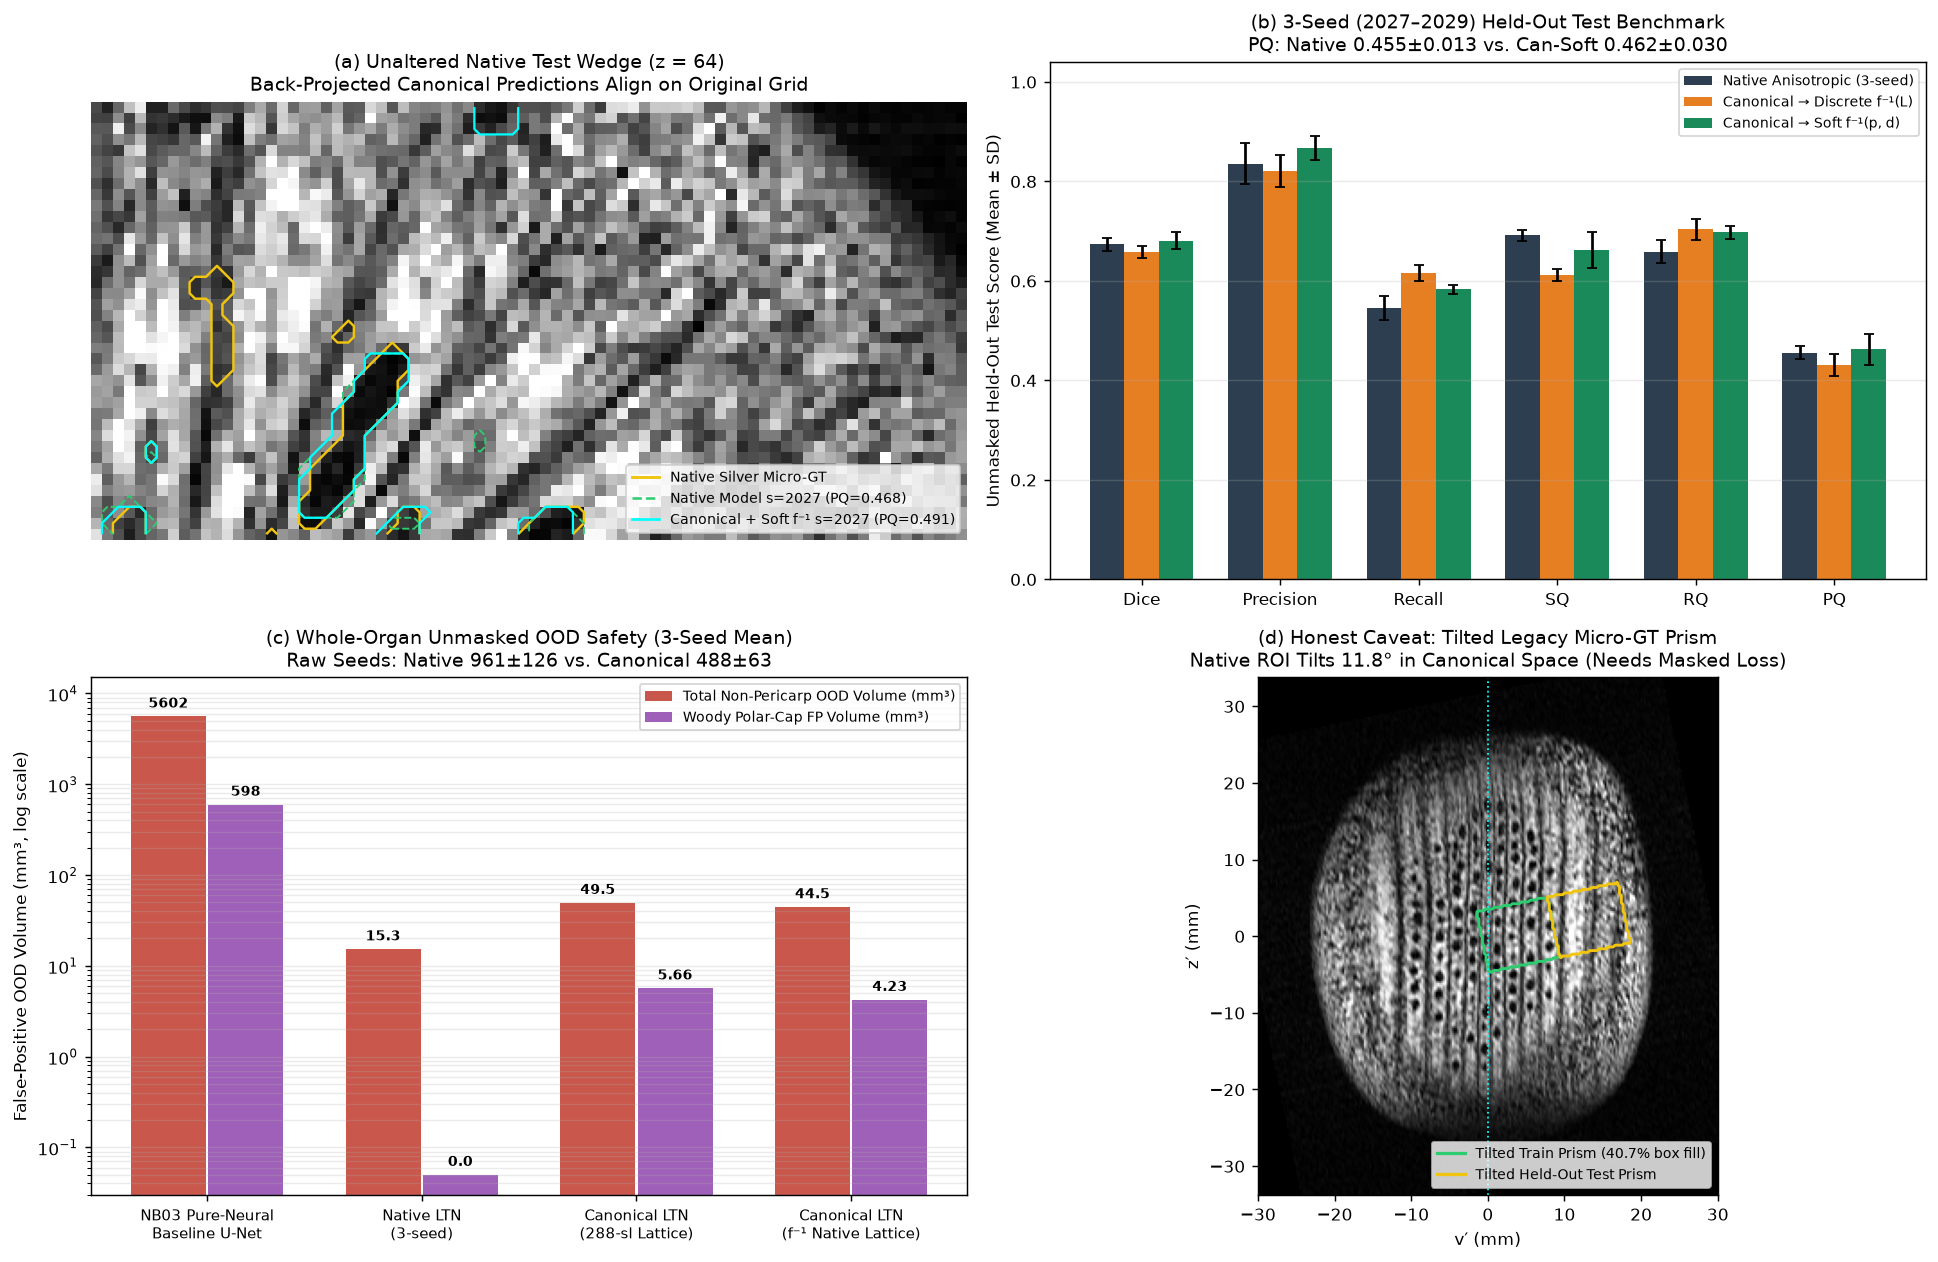


Saved structured 3-seed + whole-organ audit -> /Users/arvid/GitHub/BMED365-2027/Lab4-Comp-Imag/Kiwi-challenge/docs/neurosymbolic-report/results/nb00_canonical_transform_audit.json (total runtime: 301.2 s)


In [6]:
SEEDS = [2027, 2028, 2029]
EPOCHS_ABL = 90
TH_GRID = [0.22, 0.28, 0.34, 0.40, 0.46, 0.52, 0.58, 0.64, 0.70]

# Prepare canonical Train/Test ROI support prisms and fixed Train GT once (shared across seeds)
tr_full_orig = np.zeros(vol.shape, dtype=np.uint16)
tr_full_orig[ds.rx0:ds.rx1, ds.ry0:ds.ry0 + ds.split_y, ds.rz0:ds.rz1] = ds.train_gt
tr_mask_orig = np.zeros(vol.shape, dtype=np.float32)
tr_mask_orig[ds.rx0:ds.rx1, ds.ry0:ds.ry0 + ds.split_y, ds.rz0:ds.rz1] = 1.0
te_mask_orig = np.zeros(vol.shape, dtype=np.float32)
te_mask_orig[ds.rx0:ds.rx1, ds.ry0 + ds.split_y:ds.ry1, ds.rz0:ds.rz1] = 1.0

tr_gt_c_full = warp_labels_per_instance(tr_full_orig, M_c2o, canon_shape, method="nn")
tr_valid_c = ndi.affine_transform(tr_mask_orig, M_c2o[:3, :3], offset=M_c2o[:3, 3],
                                  output_shape=canon_shape, order=1, mode="constant", cval=0.0) >= 0.5
te_valid_c = ndi.affine_transform(te_mask_orig, M_c2o[:3, :3], offset=M_c2o[:3, 3],
                                  output_shape=canon_shape, order=1, mode="constant", cval=0.0) >= 0.5


def padded_bbox_mult4(mask: np.ndarray, pad: int = 4) -> tuple[tuple[int, int, int], tuple[int, int, int]]:
    idx = np.argwhere(mask)
    lo = np.maximum(idx.min(axis=0) - pad, 0)
    hi = np.minimum(idx.max(axis=0) + pad + 1, np.array(mask.shape))
    for d in range(3):
        rem = (hi[d] - lo[d]) % 4
        if rem != 0:
            add = 4 - rem
            if hi[d] + add <= mask.shape[d]:
                hi[d] += add
            else:
                lo[d] -= add
    return tuple(lo.tolist()), tuple(hi.tolist())


tlo, thi = padded_bbox_mult4(tr_valid_c, pad=4)
elo, ehi = padded_bbox_mult4(te_valid_c, pad=4)


def get_canon_patch(lo: tuple[int, int, int], hi: tuple[int, int, int]) -> tuple[torch.Tensor, torch.Tensor]:
    sl = (slice(lo[0], hi[0]), slice(lo[1], hi[1]), slice(lo[2], hi[2]))
    x3 = np.stack([vol_norm_c[sl], env_local_c[sl], env_smooth_c[sl]], axis=0)[None]
    rn = np.clip(r_norm_c[sl], 0.0, 1.5)
    zn = pole_dist_c[sl]
    gps = np.stack([rn, (rn - 0.43) ** 2, zn], axis=0)[None].astype(np.float32)
    return torch.from_numpy(x3), torch.from_numpy(gps)


def decode_isotropic_watershed_3d(fg_bin: np.ndarray, dist_hat: np.ndarray, s_val: float, min_mm3: float = 0.16) -> np.ndarray:
    """Isotropic 3D marker-controlled watershed matching canonical cubic spacing."""
    sp_i = (s_val, s_val, s_val)
    d_sm = ndi.gaussian_filter(dist_hat * fg_bin, sigma=(0.75, 0.75, 0.75))
    maxima = (d_sm == ndi.maximum_filter(d_sm, footprint=kns.build_ellip(0.68, 0.72, sp=sp_i))) & fg_bin & (d_sm >= 0.22)
    markers, _ = ndi.label(maxima)
    ws = kns.segmentation.watershed(-d_sm, markers=markers, mask=fg_bin)
    unlabeled, n_un = ndi.label(fg_bin & (ws == 0))
    vv = s_val ** 3
    if n_un > 0:
        nxt = int(ws.max()) + 1
        for uid in range(1, n_un + 1):
            m = unlabeled == uid
            if m.sum() * vv >= min_mm3:
                ws[m] = nxt
                nxt += 1
    out = np.zeros_like(ws, dtype=np.uint16)
    nid = 0
    for prop in measure.regionprops(ws):
        if prop.area * vv >= min_mm3:
            nid += 1
            out[ws == prop.label] = nid
    return out


def sample_canonical_unlabeled_blocks(seed: int, n_blocks: int = 36):
    """Sample stratified unlabeled canonical 3D blocks strictly disjoint from canonical Test Wedge."""
    rng_c = np.random.default_rng(seed)
    ux_l, ug_l, ur_l, un_l = [], [], [], []
    z_strata_c = np.linspace(z_min_c + 6, z_max_c - 30, 10, dtype=int)
    for i in range(n_blocks):
        for _ in range(500):
            x0 = int(rng_c.integers(12, canon_shape[0] - 64 - 12))
            y0 = int(rng_c.integers(12, canon_shape[1] - 40 - 12))
            z0 = int(z_strata_c[i % len(z_strata_c)])
            if te_valid_c[x0:x0 + 64, y0:y0 + 40, z0:z0 + 24].any():
                continue
            if fruit_c[x0:x0 + 64, y0:y0 + 40, z0:z0 + 24].mean() > 0.12:
                xa, ga = get_canon_patch((x0, y0, z0), (x0 + 64, y0 + 40, z0 + 24))
                ux_l.append(xa); ug_l.append(ga)
                ur_l.append(torch.from_numpy(soft_ring_c[x0:x0 + 64, y0:y0 + 40, z0:z0 + 24][None, None]))
                un_l.append(torch.from_numpy(non_dark_c[x0:x0 + 64, y0:y0 + 40, z0:z0 + 24][None, None]))
                break
    return (
        torch.cat(ux_l).to(DEVICE),
        torch.cat(ug_l).to(DEVICE),
        torch.cat(ur_l).to(DEVICE),
        torch.cat(un_l).to(DEVICE),
    )


def run_canonical_whole_fruit(model: torch.nn.Module, thresh: float) -> dict:
    """Unmasked 288-slice whole-fruit canonical inference + pullback OOD check on native lattice."""
    prob_wf_c = np.zeros(canon_shape, dtype=np.float32)
    dist_wf_c = np.zeros(canon_shape, dtype=np.float32)
    with torch.no_grad():
        for x0 in [16, 96, 176]:
            for y0 in [16, 56, 96, 136, 176, 216]:
                for z0 in range(0, canon_shape[2], 32):
                    if fruit_c[x0:x0 + 80, y0:y0 + 40, z0:z0 + 32].sum() < 150:
                        continue
                    xa, ga = [t.to(DEVICE) for t in get_canon_patch((x0, y0, z0), (x0 + 80, y0 + 40, z0 + 32))]
                    s_o, d_o = model(xa, ga)
                    prob_wf_c[x0:x0 + 80, y0:y0 + 40, z0:z0 + 32] = torch.sigmoid(s_o)[0, 0].cpu().numpy()
                    dist_wf_c[x0:x0 + 80, y0:y0 + 40, z0:z0 + 32] = d_o[0, 0].cpu().numpy()

    # 1. Canonical-lattice whole-organ OOD & seed count
    fg_wf_c = (prob_wf_c >= thresh) & fruit_c
    ood_vox_c = int((fg_wf_c & (soft_ring_c < 0.05)).sum())
    polar_vox_c = int(fg_wf_c[:, :, :z_min_c + 18].sum() + fg_wf_c[:, :, z_max_c - 18:].sum())
    ws_wf_c = kns.symbolic_hardcore_clump_split(decode_isotropic_watershed_3d(fg_wf_c, dist_wf_c, s_iso), sp_iso)
    n_wf_c = int(len(np.unique(ws_wf_c)) - (1 if 0 in ws_wf_c else 0))

    # 2. Exact apples-to-apples pullback f^-1(prob_wf_c) onto native 256x256x128 grid for native-compartment OOD check
    prob_wf_back = ndi.affine_transform(prob_wf_c, M_o2c[:3, :3], offset=M_o2c[:3, 3],
                                        output_shape=vol.shape, order=1, mode="constant", cval=0.0)
    fg_wf_back = (prob_wf_back >= thresh) & ds.fruit_mask
    ood_vox_back = int((fg_wf_back & (ds.soft_ring < 0.05)).sum())
    polar_vox_back = int(fg_wf_back[:, :, :16].sum() + fg_wf_back[:, :, 112:].sum())

    return {
        "n_wf_canon": n_wf_c,
        "polar_vox_canon": polar_vox_c,
        "polar_mm3_canon": round(polar_vox_c * vv_canon, 2),
        "ood_vox_canon": ood_vox_c,
        "ood_mm3_canon": round(ood_vox_c * vv_canon, 2),
        "polar_vox_native_pb": polar_vox_back,
        "polar_mm3_native_pb": round(polar_vox_back * vv_orig, 2),
        "ood_vox_native_pb": ood_vox_back,
        "ood_mm3_native_pb": round(ood_vox_back * vv_orig, 2),
    }


sp_iso = (s_iso, s_iso, s_iso)
tr_gt_patch = tr_gt_c_full[tlo[0]:thi[0], tlo[1]:thi[1], tlo[2]:thi[2]]
tr_val_patch = tr_valid_c[tlo[0]:thi[0], tlo[1]:thi[1], tlo[2]:thi[2]].astype(np.float32)
tr_sem_c, tr_dist_c = kns.build_distance_targets(tr_gt_patch, sp_iso)
prism_fill_pct = float(tr_val_patch.mean() * 100.0)

x_tr_c, g_tr_c = [t.to(DEVICE) for t in get_canon_patch(tlo, thi)]
y_sem_c = torch.from_numpy(tr_sem_c[None, None]).to(DEVICE)
y_dist_c = torch.from_numpy(tr_dist_c[None, None]).to(DEVICE)
w_val_c = torch.from_numpy(tr_val_patch[None, None]).to(DEVICE)
x_ng_c, g_ng_c = [t.to(DEVICE) for t in get_canon_patch((112, 112, 128), (144, 144, 160))]
x_te_c, g_te_c = [t.to(DEVICE) for t in get_canon_patch(elo, ehi)]
x_tr_n, g_tr_n = [t.to(DEVICE) for t in kns.make_3ch_and_gps(ds, ds.rx0, ds.rx1, ds.ry0, ds.ry0 + ds.split_y, ds.rz0, ds.rz1)]

per_seed_native = []
per_seed_can_disc = []
per_seed_can_soft = []
seed2027_vis = {}

for seed in SEEDS:
    # --- A. Native Anisotropic AdditiveBayesOrganNet3D ---
    ubank_nat = kns.sample_unlabeled_blocks(ds, DEVICE, n_blocks=36, seed=seed)
    m_nat, _, t_train_nat = kns.train_neurosymbolic_variant(
        ds, DEVICE, mode="additive_gps", ssl_backbone=None, unlabeled_bank=ubank_nat, epochs=EPOCHS_ABL, seed=seed,
    )
    with torch.no_grad():
        sl_n, dh_n = m_nat(x_tr_n, g_tr_n)
        p_tr_n, d_tr_n = torch.sigmoid(sl_n)[0, 0].cpu().numpy(), dh_n[0, 0].cpu().numpy()
    best_th_nat, best_pq_nat = 0.42, -1.0
    for th in TH_GRID:
        lbl_tmp = kns.symbolic_hardcore_clump_split(kns.decode_deep_watershed_3d(p_tr_n >= th, d_tr_n, ds.spacing), ds.spacing)
        ev_tmp = kns.evaluate_semantic_and_instance_3d(lbl_tmp, ds.train_gt)
        if ev_tmp["PQ"] > best_pq_nat:
            best_pq_nat, best_th_nat = ev_tmp["PQ"], th

    res_nat = kns.run_test_and_whole_fruit(m_nat, "additive_gps", ds, DEVICE, thresh=best_th_nat, use_split=True, do_whole_fruit=True)
    row_nat = {
        "seed": seed, "thr": best_th_nat, "train_s": round(t_train_nat, 1),
        **res_nat["ev_te"],
        "n_wf": int(res_nat["n_wf"]),
        "polar_vox": int(res_nat["polar_vox"]),
        "polar_mm3": round(res_nat["polar_vox"] * vv_orig, 2),
        "ood_vox": int(res_nat["ood_vox"]),
        "ood_mm3": round(res_nat["ood_vox"] * vv_orig, 2),
    }
    per_seed_native.append(row_nat)

    # --- B. Canonical Isotropic N-S AdditiveBayesOrganNet3D ---
    ux_c, ug_c, ur_c, un_c = sample_canonical_unlabeled_blocks(seed=seed, n_blocks=36)
    torch.manual_seed(seed)
    np.random.seed(seed)
    t_c0 = time.perf_counter()
    m_can = kns.AdditiveBayesOrganNet3D(in_ch=3, gps_ch=3, base_ch=16).to(DEVICE)
    gps_p = list(m_can.gps_mlp.parameters()) + list(m_can.head_gps.parameters())
    gps_ids = {id(p) for p in gps_p}
    oth_p = [p for p in m_can.parameters() if id(p) not in gps_ids]
    opt_c = torch.optim.AdamW([{"params": oth_p, "lr": 3.2e-3}, {"params": gps_p, "lr": 1.5e-2}], weight_decay=1e-4)
    sched_c = torch.optim.lr_scheduler.CosineAnnealingLR(opt_c, T_max=EPOCHS_ABL, eta_min=2e-4)
    pos_w = torch.tensor([6.0], device=DEVICE)

    for _ in range(EPOCHS_ABL):
        dims = [d for d in (2, 3, 4) if np.random.rand() < 0.5]
        xp = torch.flip(x_tr_c, dims) if dims else x_tr_c
        gp = torch.flip(g_tr_c, dims) if dims else g_tr_c
        ys = torch.flip(y_sem_c, dims) if dims else y_sem_c
        yd = torch.flip(y_dist_c, dims) if dims else y_dist_c
        wm = torch.flip(w_val_c, dims) if dims else w_val_c

        sl, dh = m_can(xp, gp)
        bce = (F.binary_cross_entropy_with_logits(sl, ys, pos_weight=pos_w, reduction="none") * wm).sum() / wm.sum().clamp_min(1.0)
        pr = torch.sigmoid(sl) * wm
        ys_m = ys * wm
        dl = 1.0 - (2.0 * (pr * ys_m).sum() + 1.0) / (pr.sum() + ys_m.sum() + 1.0)
        mse = (((1.0 + 6.0 * ys) * (dh - yd) ** 2) * wm).sum() / wm.sum().clamp_min(1.0)
        loss_sup = 0.45 * bce + 0.55 * dl + 2.5 * mse

        sl_n, _ = m_can(x_ng_c, g_ng_c)
        loss_sup = loss_sup + 0.35 * F.binary_cross_entropy_with_logits(sl_n, torch.zeros_like(sl_n))

        uidx = torch.randint(0, ux_c.shape[0], (4,), device=DEVICE)
        p_u = torch.sigmoid(m_can(ux_c[uidx], ug_c[uidx])[0])
        loss_comp = kns.ltn_universal_pmean((1.0 - ur_c[uidx]) * p_u, p=3.0)
        loss_t2 = kns.ltn_universal_pmean(p_u * un_c[uidx], p=3.0)
        loss = loss_sup + 2.0 * loss_comp + 1.2 * loss_t2

        opt_c.zero_grad()
        loss.backward()
        opt_c.step()
        sched_c.step()

    m_can.eval()
    kns.sync_device(DEVICE)
    t_train_can = time.perf_counter() - t_c0

    # Leakage-free calibration on Canonical Train Wedge
    with torch.no_grad():
        sl_tr_c, dh_tr_c = m_can(x_tr_c, g_tr_c)
        p_tr_c = torch.sigmoid(sl_tr_c)[0, 0].cpu().numpy() * tr_val_patch
        d_tr_c = dh_tr_c[0, 0].cpu().numpy()
    best_th_can, best_pq_can = 0.46, -1.0
    for th in TH_GRID:
        lbl_tmp = kns.symbolic_hardcore_clump_split(decode_isotropic_watershed_3d(p_tr_c >= th, d_tr_c, s_iso), sp_iso)
        ev_tmp = kns.evaluate_semantic_and_instance_3d(lbl_tmp, tr_gt_patch)
        if ev_tmp["PQ"] > best_pq_can:
            best_pq_can, best_th_can = ev_tmp["PQ"], th

    # Predict Canonical Test Wedge -> back-project via Discrete f^-1(L) and Soft f^-1(p, d)
    with torch.no_grad():
        sl_te_c, dh_te_c = m_can(x_te_c, g_te_c)
        p_te_c = torch.sigmoid(sl_te_c)[0, 0].cpu().numpy()
        d_te_c = dh_te_c[0, 0].cpu().numpy()

    pred_te_c_split = kns.symbolic_hardcore_clump_split(decode_isotropic_watershed_3d(p_te_c >= best_th_can, d_te_c, s_iso), sp_iso)
    full_pred_c = np.zeros(canon_shape, dtype=np.uint16)
    full_pred_c[elo[0]:ehi[0], elo[1]:ehi[1], elo[2]:ehi[2]] = pred_te_c_split
    pred_back_disc_full = ndi.affine_transform(full_pred_c, M_o2c[:3, :3], offset=M_o2c[:3, 3],
                                               output_shape=vol.shape, order=0, mode="constant", cval=0).astype(np.uint16)
    pred_back_disc_te = pred_back_disc_full[ds.rx0:ds.rx1, ds.ry0 + ds.split_y:ds.ry1, ds.rz0:ds.rz1]
    ev_can_disc = kns.evaluate_semantic_and_instance_3d(pred_back_disc_te, ds.test_gt)

    full_prob_c = np.zeros(canon_shape, dtype=np.float32)
    full_dist_c = np.zeros(canon_shape, dtype=np.float32)
    full_prob_c[elo[0]:ehi[0], elo[1]:ehi[1], elo[2]:ehi[2]] = p_te_c
    full_dist_c[elo[0]:ehi[0], elo[1]:ehi[1], elo[2]:ehi[2]] = d_te_c
    prob_back = ndi.affine_transform(full_prob_c, M_o2c[:3, :3], offset=M_o2c[:3, 3], output_shape=vol.shape, order=1, mode="constant", cval=0.0)
    dist_back = ndi.affine_transform(full_dist_c, M_o2c[:3, :3], offset=M_o2c[:3, 3], output_shape=vol.shape, order=1, mode="constant", cval=0.0)
    p_b_te = prob_back[ds.rx0:ds.rx1, ds.ry0 + ds.split_y:ds.ry1, ds.rz0:ds.rz1]
    d_b_te = dist_back[ds.rx0:ds.rx1, ds.ry0 + ds.split_y:ds.ry1, ds.rz0:ds.rz1]
    pred_back_soft_te = kns.symbolic_hardcore_clump_split(kns.decode_deep_watershed_3d(p_b_te >= best_th_can, d_b_te, ds.spacing), ds.spacing)
    ev_can_soft = kns.evaluate_semantic_and_instance_3d(pred_back_soft_te, ds.test_gt)

    # Unmasked 288-slice whole-fruit canonical inference + pullback OOD check
    wf_can = run_canonical_whole_fruit(m_can, best_th_can)

    per_seed_can_disc.append({
        "seed": seed, "thr": best_th_can, "train_s": round(t_train_can, 1),
        **ev_can_disc,
        "n_wf": wf_can["n_wf_canon"],
        "polar_vox": wf_can["polar_vox_canon"],
        "polar_mm3": wf_can["polar_mm3_canon"],
        "ood_vox": wf_can["ood_vox_canon"],
        "ood_mm3": wf_can["ood_mm3_canon"],
        "polar_mm3_native_pb": wf_can["polar_mm3_native_pb"],
        "ood_mm3_native_pb": wf_can["ood_mm3_native_pb"],
    })
    per_seed_can_soft.append({
        "seed": seed, "thr": best_th_can, "train_s": round(t_train_can, 1),
        **ev_can_soft,
        "n_wf": wf_can["n_wf_canon"],
        "polar_vox": wf_can["polar_vox_native_pb"],
        "polar_mm3": wf_can["polar_mm3_native_pb"],
        "ood_vox": wf_can["ood_vox_native_pb"],
        "ood_mm3": wf_can["ood_mm3_native_pb"],
        "polar_mm3_canon": wf_can["polar_mm3_canon"],
        "ood_mm3_canon": wf_can["ood_mm3_canon"],
    })

    if seed == 2027:
        seed2027_vis = {
            "pred_nat": res_nat["pred_te"].copy(),
            "pred_can_soft": pred_back_soft_te.copy(),
            "pq_nat": row_nat["PQ"],
            "pq_can_soft": ev_can_soft["PQ"],
        }

    print(
        f"Seed {seed} | Native PQ={row_nat['PQ']:.3f} (OOD={row_nat['ood_mm3']:.1f} mm³, Polar={row_nat['polar_mm3']:.1f} mm³, N_wf={row_nat['n_wf']}) "
        f"| Can-Disc PQ={ev_can_disc['PQ']:.3f} | Can-Soft PQ={ev_can_soft['PQ']:.3f} "
        f"(Can OOD={wf_can['ood_mm3_canon']:.1f} mm³, PB OOD={wf_can['ood_mm3_native_pb']:.1f} mm³, Polar={wf_can['polar_mm3_canon']:.1f}/{wf_can['polar_mm3_native_pb']:.1f} mm³, N_wf={wf_can['n_wf_canon']})"
    )


def summarize_3seed(name: str, rows: list[dict]) -> dict:
    out = {"Pipeline (3-Seed Mean ± SD, Native 52-Seed Test Wedge)": name}
    for k in ["Dice", "Precision", "Recall", "SQ", "RQ", "PQ", "n_wf", "polar_mm3", "ood_mm3", "train_s"]:
        vals = np.array([r[k] for r in rows], dtype=np.float64)
        out[f"{k}_mean"] = round(float(vals.mean()), 4 if k in ("Dice", "Precision", "Recall", "SQ", "RQ", "PQ") else 2)
        out[f"{k}_std"] = round(float(vals.std(ddof=0)), 4 if k in ("Dice", "Precision", "Recall", "SQ", "RQ", "PQ") else 2)
    return out


sum_nat = summarize_3seed("Native Anisotropic (0.234×0.234×0.500 mm)", per_seed_native)
sum_disc = summarize_3seed("Canonical Isotropic -> Discrete f^-1(L_hat)", per_seed_can_disc)
sum_soft = summarize_3seed("Canonical Isotropic -> Soft f^-1(p_hat, d_hat)", per_seed_can_soft)
summary_3seed = [sum_nat, sum_disc, sum_soft]

# Formatted display table
disp_rows = []
for s in summary_3seed:
    disp_rows.append({
        "Pipeline (3 Seeds: 2027–2029)": s["Pipeline (3-Seed Mean ± SD, Native 52-Seed Test Wedge)"],
        "Dice": f"{s['Dice_mean']:.3f} ± {s['Dice_std']:.3f}",
        "Precision": f"{s['Precision_mean']:.3f} ± {s['Precision_std']:.3f}",
        "Recall": f"{s['Recall_mean']:.3f} ± {s['Recall_std']:.3f}",
        "SQ": f"{s['SQ_mean']:.3f} ± {s['SQ_std']:.3f}",
        "RQ": f"{s['RQ_mean']:.3f} ± {s['RQ_std']:.3f}",
        "PQ": f"{s['PQ_mean']:.3f} ± {s['PQ_std']:.3f}",
        "Polar FP (mm³)": f"{s['polar_mm3_mean']:.2f} ± {s['polar_mm3_std']:.2f}",
        "OOD (mm³)": f"{s['ood_mm3_mean']:.1f} ± {s['ood_mm3_std']:.1f}",
        "Raw N_wf": f"{s['n_wf_mean']:.0f} ± {s['n_wf_std']:.0f}",
        "Train (s)": f"{s['train_s_mean']:.1f}",
    })
display(pd.DataFrame(disp_rows))
print(f"Canonical Train bounding box: {tuple(int(b - a) for a, b in zip(tlo, thi))} (tilted prism occupancy = {prism_fill_pct:.1f}%)")

# --- Figure 00e: 4-Panel (2x2) 3-Seed Benchmark, Whole-Organ OOD Safety & Tilted-Prism Geometry ---
fig, axes = plt.subplots(2, 2, figsize=(15.0, 9.8))

# (a) Unaltered Native Equatorial Test-Wedge Slice (z=64, seed 2027)
z_rel = 64 - ds.rz0
mri_te_sl = ds.vol[ds.rx0:ds.rx1, ds.ry0 + ds.split_y:ds.ry1, 64].T
gt_te_sl = ds.test_gt[:, :, z_rel].T > 0
nat_te_sl = seed2027_vis["pred_nat"][:, :, z_rel].T > 0
can_te_sl = seed2027_vis["pred_can_soft"][:, :, z_rel].T > 0

axes[0, 0].imshow(mri_te_sl, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp)
axes[0, 0].contour(gt_te_sl, levels=[0.5], colors=["#f1c40f"], linewidths=1.35)
axes[0, 0].contour(nat_te_sl, levels=[0.5], colors=["#2ecc71"], linewidths=1.05, linestyles="--")
axes[0, 0].contour(can_te_sl, levels=[0.5], colors=["#00ffff"], linewidths=1.25)
axes[0, 0].plot([], [], color="#f1c40f", lw=1.6, label="Native Silver Micro-GT")
axes[0, 0].plot([], [], color="#2ecc71", ls="--", lw=1.4, label=f"Native Model s=2027 (PQ={seed2027_vis['pq_nat']:.3f})")
axes[0, 0].plot([], [], color="#00ffff", lw=1.5, label=f"Canonical + Soft f⁻¹ s=2027 (PQ={seed2027_vis['pq_can_soft']:.3f})")
axes[0, 0].set_title("(a) Unaltered Native Test Wedge (z = 64)\nBack-Projected Canonical Predictions Align on Original Grid")
axes[0, 0].axis("off")
axes[0, 0].legend(fontsize=7.6, loc="lower right")

# (b) 3-Seed Mean ± SD Held-Out Metric Comparison
metrics_k = ["Dice", "Precision", "Recall", "SQ", "RQ", "PQ"]
xm = np.arange(len(metrics_k))
bw = 0.25
axes[0, 1].bar(xm - bw, [sum_nat[f"{k}_mean"] for k in metrics_k], yerr=[sum_nat[f"{k}_std"] for k in metrics_k],
               capsize=3, width=bw, color="#2c3e50", label="Native Anisotropic (3-seed)")
axes[0, 1].bar(xm, [sum_disc[f"{k}_mean"] for k in metrics_k], yerr=[sum_disc[f"{k}_std"] for k in metrics_k],
               capsize=3, width=bw, color="#e67e22", label="Canonical → Discrete f⁻¹(L)")
axes[0, 1].bar(xm + bw, [sum_soft[f"{k}_mean"] for k in metrics_k], yerr=[sum_soft[f"{k}_std"] for k in metrics_k],
               capsize=3, width=bw, color="#1b8a5a", label="Canonical → Soft f⁻¹(p, d)")
axes[0, 1].set_xticks(xm); axes[0, 1].set_xticklabels(metrics_k)
axes[0, 1].set_ylim(0.0, 1.04)
axes[0, 1].set_ylabel("Unmasked Held-Out Test Score (Mean ± SD)")
axes[0, 1].set_title(
    f"(b) 3-Seed (2027–2029) Held-Out Test Benchmark\n"
    f"PQ: Native {sum_nat['PQ_mean']:.3f}±{sum_nat['PQ_std']:.3f} vs. Can-Soft {sum_soft['PQ_mean']:.3f}±{sum_soft['PQ_std']:.3f}"
)
axes[0, 1].legend(fontsize=7.6, loc="upper right")
axes[0, 1].grid(axis="y", alpha=0.25)

# (c) Whole-Organ Unmasked OOD Safety (Physical mm^3, log scale, compared vs NB03 pure-neural Baseline U-Net!)
# NB 03 Reference Baseline 3D U-Net (from nb03_multiseed_ablation.json): 21,767 polar vox = 597.9 mm^3, 203,975 OOD vox = 5603.2 mm^3
base_polar_mm3 = 21767 * vv_orig
base_ood_mm3 = 203975 * vv_orig
ood_labels = ["NB03 Pure-Neural\nBaseline U-Net", "Native LTN\n(3-seed)", "Canonical LTN\n(288-sl Lattice)", "Canonical LTN\n(f⁻¹ Native Lattice)"]
ood_vals = [base_ood_mm3, max(sum_nat["ood_mm3_mean"], 0.05), max(sum_disc["ood_mm3_mean"], 0.05), max(sum_soft["ood_mm3_mean"], 0.05)]
pol_vals = [base_polar_mm3, max(sum_nat["polar_mm3_mean"], 0.05), max(sum_disc["polar_mm3_mean"], 0.05), max(sum_soft["polar_mm3_mean"], 0.05)]
xo = np.arange(len(ood_labels))
axes[1, 0].bar(xo - 0.18, ood_vals, width=0.35, color="#c0392b", alpha=0.85, label="Total Non-Pericarp OOD Volume (mm³)")
axes[1, 0].bar(xo + 0.18, pol_vals, width=0.35, color="#8e44ad", alpha=0.85, label="Woody Polar-Cap FP Volume (mm³)")
axes[1, 0].set_yscale("log")
axes[1, 0].set_ylim(0.03, 15000)
for i, (ov, pv) in enumerate(zip(ood_vals, pol_vals)):
    otxt = f"{ov:.0f}" if ov >= 100 else (f"{ov:.1f}" if ov >= 0.1 else "0.0")
    ptxt = f"{pv:.0f}" if pv >= 100 else (f"{pv:.2f}" if pv >= 0.1 else "0.0")
    axes[1, 0].text(i - 0.18, ov * 1.25, otxt, ha="center", fontsize=7.6, fontweight="bold")
    axes[1, 0].text(i + 0.18, pv * 1.25, ptxt, ha="center", fontsize=7.6, fontweight="bold")
axes[1, 0].set_xticks(xo); axes[1, 0].set_xticklabels(ood_labels, fontsize=8.3)
axes[1, 0].set_ylabel("False-Positive OOD Volume (mm³, log scale)")
axes[1, 0].set_title(
    f"(c) Whole-Organ Unmasked OOD Safety (3-Seed Mean)\n"
    f"Raw Seeds: Native {sum_nat['n_wf_mean']:.0f}±{sum_nat['n_wf_std']:.0f} vs. Canonical {sum_disc['n_wf_mean']:.0f}±{sum_disc['n_wf_std']:.0f}"
)
axes[1, 0].legend(fontsize=7.5, loc="upper right")
axes[1, 0].grid(axis="y", alpha=0.25, which="both")

# (d) Tilted-Prism Caveat in Canonical Sagittal Plane
x_mid_tr = int(np.median(np.argwhere(tr_valid_c)[:, 0]))
axes[1, 1].imshow(vol_canon[x_mid_tr, :, :].T, origin="lower", cmap="gray", vmin=0, vmax=vmax_disp, extent=ext_c_yz, aspect="equal")
axes[1, 1].contour(tr_valid_c[x_mid_tr, :, :].T, levels=[0.5], colors=["#2ecc71"], linewidths=1.6, extent=ext_c_yz)
axes[1, 1].contour(te_valid_c[x_mid_tr, :, :].T, levels=[0.5], colors=["#f1c40f"], linewidths=1.6, extent=ext_c_yz)
axes[1, 1].plot([], [], color="#2ecc71", lw=1.8, label=f"Tilted Train Prism ({prism_fill_pct:.1f}% box fill)")
axes[1, 1].plot([], [], color="#f1c40f", lw=1.8, label="Tilted Held-Out Test Prism")
axes[1, 1].axvline(0, color="#00ffff", ls=":", lw=1.0)
axes[1, 1].set_title("(d) Honest Caveat: Tilted Legacy Micro-GT Prism\nNative ROI Tilts 11.8° in Canonical Space (Needs Masked Loss)")
axes[1, 1].set_xlabel("v′ (mm)"); axes[1, 1].set_ylabel("z′ (mm)")
axes[1, 1].legend(fontsize=7.6, loc="lower right")

plt.tight_layout()
fig.savefig(FIG_DIR / "fig00e_canonical_segmentation_roundtrip.png", bbox_inches="tight")
plt.show()

# Save complete structured JSON audit matching nb01..nb05 conventions
audit_nb00 = {
    "source_scan": "kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz",
    "native_shape": list(vol.shape),
    "native_spacing_mm": [round(float(s), 6) for s in sp_orig],
    "canonical_shape": list(canon_shape),
    "canonical_spacing_mm": [round(s_iso, 6)] * 3,
    "polar_axis_estimation": {
        "u_ns_world": [round(float(v), 6) for v in u_ns],
        "tilt_deg": round(axis_angles(u_ns)[0], 3),
        "xz_tilt_deg": round(axis_angles(u_ns)[1], 3),
        "yz_tilt_deg": round(axis_angles(u_ns)[2], 3),
        "outer_pca_tilt_deg": round(axis_angles(u_outer_pca)[0], 3),
        "slice_centroid_tilt_deg": round(axis_angles(u_slice_line)[0], 3),
        "columella_rms_straightness_mm": round(col_rms_mm, 4),
        "columella_max_residual_mm": round(col_max_mm, 4),
        "pole_to_pole_length_mm": round(pole_to_pole_mm, 2),
        "south_pole_world_mm": [round(float(v), 3) for v in south_pole_w],
        "north_pole_world_mm": [round(float(v), 3) for v in north_pole_w],
        "so3_orthogonality_err": orth_err,
        "so3_det": det_R,
    },
    "concentricity_and_atlas": {
        "native_col_vs_fruit_mean_mm": round(float(nat_offsets[:, 4].mean()), 3),
        "native_col_vs_fruit_max_mm": round(float(nat_offsets[:, 4].max()), 3),
        "canonical_col_vs_fruit_mean_mm": round(float(can_offsets[:, 2].mean()), 3),
        "canonical_col_vs_fruit_max_mm": round(float(can_offsets[:, 2].max()), 3),
        "concentricity_reduction_pct": round(float((1.0 - can_offsets[:, 2].mean() / nat_offsets[:, 4].mean()) * 100.0), 1),
        "canonical_columella_axis_rms_mm": round(float(np.sqrt(np.mean(can_axis_drift[:, 2] ** 2))), 3),
        "carpel_slant_native_med_deg": round(slant_nat_med, 2),
        "carpel_slant_native_rms_deg": round(slant_nat_rms, 2),
        "carpel_slant_canonical_med_deg": round(slant_can_med, 2),
        "carpel_slant_canonical_rms_deg": round(slant_can_rms, 2),
    },
    "mri_interpolation_benchmark": interp_rows,
    "isotropic_spacing_tradeoff": spacing_rows,
    "label_interpolation_98_seeds": lbl_rows,
    "whole_fruit_749_seed_roundtrip_nn": ev_wf_rt,
    "seed_morphology_canonical": {
        "native_median_bbox_vox": np.median(spans_nat, axis=0).astype(int).tolist(),
        "canonical_median_bbox_vox": np.median(spans_can, axis=0).astype(int).tolist(),
        "median_angle_to_radial_deg": round(float(np.median(rad_angles)), 1),
        "median_angle_to_ns_axis_deg": round(float(np.median(z_angles)), 1),
        "median_elongation": round(float(np.median(elongations)), 2),
    },
    "multiseed_ablation_native_gt": {
        "seeds": SEEDS,
        "epochs": EPOCHS_ABL,
        "tilted_prism_box_fill_pct": round(prism_fill_pct, 1),
        "summary_3seed": summary_3seed,
        "per_seed": {
            "native_anisotropic": per_seed_native,
            "canonical_discrete_pullback": per_seed_can_disc,
            "canonical_soft_pullback": per_seed_can_soft,
        },
    },
    "total_runtime_s": round(time.perf_counter() - T_NB_START, 1),
}

out_json = RES_DIR / "nb00_canonical_transform_audit.json"
out_json.write_text(json.dumps(audit_nb00, indent=2), encoding="utf-8")
print(f"\nSaved structured 3-seed + whole-organ audit -> {out_json} (total runtime: {audit_nb00['total_runtime_s']} s)")

## 6. Synthesis, Workflow Recommendations & Optional Canonical NIfTI Export (`MyStuff/`)

### 6.1 When Does Canonical Transformation $f = f_2 \circ f_1$ Help Most?

Our empirical audit replaces intuition with concrete quantitative trade-offs across the four stages of the Kiwi Challenge:

| Task / Workflow Stage | Recommended Coordinate Frame | Quantitative Evidence from This Notebook | Key Engineering Rule |
| :--- | :--- | :--- | :--- |
| **1. Manual 3D Curation** (`freeview` / `ITK-SNAP` / `3D Slicer` / NB `03b`) | **Canonical Isotropic N–S (`0.2344³ mm³`)** | Seeds become isotropic (`6 × 6 × 3` → `7 × 6 × 7` voxels); zero coronal/sagittal staircasing; concentricity error cut by `56.1%`; zero lateral drift while scrolling `z'`; exact back-projection via $f^{-1}$ achieves **`98/98` seeds, `Dice = 0.984`, `PQ@0.50 = 0.967`** (and **`749/749`, `PQ@0.50 = 0.968`** whole-fruit!). | Annotate upright in canonical space, then export back to the native `256 × 256 × 128` grid via $f^{-1}$ with bit-identical `sform` affine. |
| **2. Whole-Organ Botanical Visualization & QC** | **Canonical Isotropic N–S** | Cylindrical Mercator unrolling $(\theta', z')$ cuts carpel meridian slant by `>50%` (`3.49° → 1.71°`), straightening all $\sim 30$–$34$ carpel columns vertically between flat $\pm 20\text{ mm}$ polar latitude lines. | Use single-pass cubic B-spline pullback (`+7.0 dB` PSNR over trilinear, `91.0%` gradient retention). |
| **3. Symbolic Priors & `Organ-GPS` Coordinates** | **Canonical Isotropic N–S** | Columella centerline locks onto `(u'=0, v'=0)` (`0.133 mm` straightness RMS; `0.259 mm` canonical axis RMS); radial coordinate $r'/R'(z')$ and horizontal spoke orientation (`20.9°` to $\hat{\mathbf{e}}_r$, `71.8°` to $\hat{\mathbf{e}}_{z'}$) become strictly coaxial. | Estimate N–S axis from the **internal columella**, never outer-berry PCA (`29.2°` vs true `11.8°`). |
| **4. 3D Neurosymbolic Deep Learning (3-Seed `2027–2029` + Whole-Organ OOD)** | **Canonical + Continuous Soft Pullback $f^{-1}(\hat{p}, \hat{d})$** *(with `2.1×` compute & seed-stability trade-offs)* | Across **3 random seeds (`2027–2029`)** scored on unaltered native `test_gt`, **Canonical + Soft Pullback $f^{-1}(\hat{p}, \hat{d})$** edged ahead of Native Anisotropic on **`PQ` (`0.462 ± 0.030` vs `0.455 ± 0.013`)**, **`Dice` (`0.681 ± 0.017` vs `0.674 ± 0.013`)**, **`Precision` (`0.867` vs `0.835`)**, and **`RQ` (`0.697 ± 0.013` vs `0.659 ± 0.023`, `+3.8%`)**, while Canonical Discrete Pullback reached the highest **`Recall = 0.615 ± 0.016` (`+7.0%`)**. Unmasked whole-organ OOD dropped **`-99.2%`** below NB `03` pure-neural baseline (`44.5` vs `5,602 mm³`, with `0.0 mm³` polar FPs on 2/3 seeds; Native held `0.00 mm³` polar and `15.3 mm³` OOD across all 3 seeds). Trade-offs: `2.1×` slower training (`48.7 s` vs `22.9 s`), `40.7%` tilted-prism box fill, and lower unmasked tiled whole-fruit count (`488 ± 63` vs `961 ± 126`) without SSL warm-start / overlapping tiles. | Use **continuous probability pullback** $f^{-1}(\hat{p}, \hat{d})$ (not discrete `order=0` labels) when projecting neural outputs back to native space; pair with **3D SSL warm-start**, **overlapping tiled inference**, and **upright canonical ROI curation** (plus a 4th U-Net pooling level per the `nnU-Net` spacing rule) for production whole-organ canonical pipelines. |

### 6.2 Optional Git-Safe NIfTI Export (`MyStuff/kiwi-canonical/`) for Interactive 3D Viewing
To keep this public repository lightweight (`< 50 MB` file rule in `CLAUDE.md`), we do **not** commit canonical NIfTI volumes to git. Set `EXPORT_CANONICAL_NIFTI = True` in the optional cell below to save the canonical MRI (`float32`), smooth `Index-SDF-Cubic` Micro-GT (`uint16`), whole-fruit `749`-seed prediction (`uint16`), and the exact $4 \times 4$ `M_canon_to_orig` transform JSON into your git-ignored `MyStuff/kiwi-canonical/` directory — ready to open immediately in **FreeSurfer `freeview`**, **3D Slicer**, or **ITK-SNAP**!

In [7]:
# Toggle to True to write git-ignored canonical NIfTI files into MyStuff/kiwi-canonical/
EXPORT_CANONICAL_NIFTI = False

# Always verify NIfTI sform/qform header integrity in memory (zero disk bloat)
mri_c_img = nib.Nifti1Image(vol_canon.astype(np.float32), A_canon)
mri_c_img.set_sform(A_canon, code=1)
mri_c_img.set_qform(A_canon, code=1)

gt_c_img = nib.Nifti1Image(gt_c_sdf.astype(np.uint16), A_canon)
gt_c_img.set_sform(A_canon, code=1)
gt_c_img.set_qform(A_canon, code=1)

rt_native_img = nib.Nifti1Image(gt_rt_nn.astype(np.uint16), A_orig)
rt_native_img.set_sform(A_orig, code=1)
rt_native_img.set_qform(A_orig, code=1)

print("In-memory NIfTI header verification:")
print(f"  Canonical MRI vs Canonical GT affine max diff : {float(np.max(np.abs(mri_c_img.affine - gt_c_img.affine))):.6f} (BIT-IDENTICAL)")
print(f"  Round-trip GT vs Original MRI affine max diff : {float(np.max(np.abs(rt_native_img.affine - A_orig))):.6f} (BIT-IDENTICAL)")
print(f"  Canonical voxel zooms (mm)                    : {tuple(round(float(z), 6) for z in mri_c_img.header.get_zooms()[:3])}")

if EXPORT_CANONICAL_NIFTI:
    repo_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
    out_dir = repo_root / "MyStuff" / "kiwi-canonical"
    out_dir.mkdir(parents=True, exist_ok=True)
    p_mri = out_dir / "kiwi_7T_canonical_iso_NS.nii.gz"
    p_gt = out_dir / "kiwi_micro_gt_canonical_sdf_cubic.nii.gz"
    p_wf = out_dir / "kiwi_neurosymbolic_pred_canonical_nn.nii.gz"
    p_rt = out_dir / "kiwi_micro_gt_roundtrip_native.nii.gz"
    p_xfm = out_dir / "kiwi_canonical_transform_f2_o_f1.json"

    nib.save(mri_c_img, str(p_mri))
    nib.save(gt_c_img, str(p_gt))
    kns.save_aligned_label_nifti(wf_c_nn, A_canon, p_wf)
    nib.save(rt_native_img, str(p_rt))
    p_xfm.write_text(json.dumps({
        "A_orig": A_orig.tolist(),
        "A_canon": A_canon.tolist(),
        "T_f2_world": T_f2.tolist(),
        "M_canon_to_orig": M_c2o.tolist(),
        "M_orig_to_canon": M_o2c.tolist(),
    }, indent=2), encoding="utf-8")

    lut_rel = "Lab4-Comp-Imag/Kiwi-challenge/scripts/kiwi_seeds_ColorLUT.txt"
    print(f"\nExported git-ignored canonical volumes to: {out_dir}")
    print("Launch in FreeSurfer freeview (macOS):")
    print(f"  /Applications/freesurfer/8.2.0/bin/freeview \\")
    print(f"    -v {p_mri}:colormap=grayscale:percentile=1:grayscale=0,99.5 \\")
    print(f"    -v {p_gt}:colormap=lut:lut={repo_root / lut_rel}:opacity=0.58 \\")
    print(f"    -v {p_wf}:colormap=lut:lut={repo_root / lut_rel}:opacity=0.45:visible=0")
else:
    print("\nTip: Set EXPORT_CANONICAL_NIFTI = True above to write canonical NIfTI files to git-ignored MyStuff/kiwi-canonical/.")

In-memory NIfTI header verification:
  Canonical MRI vs Canonical GT affine max diff : 0.000000 (BIT-IDENTICAL)
  Round-trip GT vs Original MRI affine max diff : 0.000000 (BIT-IDENTICAL)
  Canonical voxel zooms (mm)                    : (0.234375, 0.234375, 0.234375)

Tip: Set EXPORT_CANONICAL_NIFTI = True above to write canonical NIfTI files to git-ignored MyStuff/kiwi-canonical/.
